# DSC 411/511 Project
# Notebook 01: Exploratory Data Analysis and Cleaning

**Class topics used:** Lecture 03 (missing values, duplicates, outliers, noise, discretization,
encoding, log transform, aggregation), Lecture 07 Section 11 (leakage), Lecture 13 (outlier and
anomaly detection: z-score, IQR, contextual anomalies, Isolation Forest).

---

This notebook answers five practical questions before any model is trained:

1. **Which rows are not real or not usable?** (duplicates, errors, impossible values)
2. **Which columns are missing, and is the blank information or a real loss?**
3. **Which values are placeholders or unusual?**
4. **Which columns do we drop, which do we impute, and with what value?**
5. **Which columns leak the outcome and must never be used as features?**

Every decision is written into a log table, so the reader can see the row count before and
after each step.

---
# Section 0: Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import geopandas as gpd

from sklearn.ensemble import IsolationForest
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 120)
sns.set_style('whitegrid')
SEED = 42

PROJECT_DIR = Path('/Users/home/workspace/School/DataMining/nfip_claims')
RAW_DIR = PROJECT_DIR / 'data_raw'
PROCESSED_DIR = PROJECT_DIR / 'data_processed'
TABLE_DIR = PROJECT_DIR / 'tables'
FIGURE_DIR = PROJECT_DIR / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

claims = pd.read_parquet(PROCESSED_DIR / 'claims_merged_2020_2025.parquet')
print(f'Rows: {len(claims):,}   Columns: {claims.shape[1]}')

Rows: 276,119   Columns: 117


**The train / test rule used in the whole project.** Models are trained on losses from
**2020-2023** and tested on **2024-2025**. Any value we learn from the data (a median for
imputation, a percentile for a threshold) is learned from **2020-2023 only**. This avoids
leakage type 2 from Lecture 07: "preprocessing before the split".

In [2]:
claims['loss_year'] = claims['dateOfLoss'].dt.year
TRAIN_YEARS = [2020, 2021, 2022, 2023]
claims['is_train_period'] = claims['loss_year'].isin(TRAIN_YEARS)
print(claims.groupby('is_train_period').size().rename('rows').to_string())

is_train_period
False    114969
True     161150


---
# Section 1: What Columns Do We Have?

We sort the 84 NFIP columns and the new external columns into groups. The group decides
how a column may be used later.

In [3]:
COLUMN_GROUPS = {
    'identifier / admin': ['id', 'asOfDate', 'nfipRatedCommunityNumber', 'nfipCommunityNumberCurrent',
                           'nfipCommunityName', 'reportedCity', 'reportedZipCode', 'countyCode', 'censusGeoid',
                           'point_id', 'block_group_geoid', 'tract_geoid', 'county_geoid', 'acs_join_level'],
    'event identifier': ['floodEvent', 'eventDesignationNumber', 'ficoNumber', 'storm_id', 'storm_name'],
    'date': ['dateOfLoss', 'yearOfLoss', 'loss_year', 'originalConstructionDate', 'originalNBDate'],
    'location': ['state', 'latitude', 'longitude'],
    'building (pre-loss)': ['occupancyType', 'numberOfFloorsInTheInsuredBuilding', 'foundationType',
                            'basementEnclosureCrawlspaceType', 'elevatedBuildingIndicator', 'obstructionType',
                            'postFIRMConstructionIndicator', 'preFirmIndicator', 'buildingDescriptionCode',
                            'numberOfUnits', 'floodproofedIndicator', 'locationOfContents',
                            'agricultureStructureIndicator', 'houseWorship', 'nonProfitIndicator',
                            'smallBusinessIndicatorBuilding', 'stateOwnedIndicator', 'buildingReplacementCost',
                            'contentsReplacementCost', 'replacementCostBasis'],
    'flood map / elevation (pre-loss)': ['ratedFloodZone', 'floodZoneCurrent', 'elevationDifference',
                                         'baseFloodElevation', 'lowestFloorElevation', 'lowestAdjacentGrade',
                                         'elevationCertificateIndicator'],
    'policy (pre-loss)': ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'buildingDeductibleCode',
                          'contentsDeductibleCode', 'rateMethod', 'crsClassCode', 'primaryResidenceIndicator',
                          'rentalPropertyIndicator', 'condominiumCoverageTypeCode', 'policyCount', 'iccCoverage',
                          'disasterAssistanceCoverageRequired'],
    'adjuster findings (post-loss)': ['buildingDamageAmount', 'contentsDamageAmount', 'buildingPropertyValue',
                                      'contentsPropertyValue', 'waterDepth', 'exteriorWaterDepth', 'interiorWaterDepth',
                                      'floodWaterDuration', 'floodCharacteristicsIndicator', 'causeOfDamage'],
    'payment / settlement (post-loss)': ['amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim',
                                         'amountPaidOnIncreasedCostOfComplianceClaim', 'netBuildingPaymentAmount',
                                         'netContentsPaymentAmount', 'netIccPaymentAmount', 'nonPaymentReasonBuilding',
                                         'nonPaymentReasonContents', 'openDate', 'mostRecentPaymentDate',
                                         'mostRecentRecoveryDate', 'totalSalvageRecovery', 'totalBldgClaimPmtRecovery',
                                         'totalContentsClaimPmtRecovery', 'totalIccClaimPmtRecovery',
                                         'totalSubrogationRecovery'],
    'external: rain (PRISM)': [c for c in claims.columns if c.startswith('rain_')],
    'external: storm (HURDAT2)': [c for c in claims.columns if c.startswith('storm_') and c not in ('storm_id', 'storm_name')],
    'external: coast': ['coast_distance_km'],
    'external: census (ACS)': [c for c in claims.columns if c.startswith('acs_') and c != 'acs_join_level'],
    'external: county risk (NRI)': [c for c in claims.columns if c.startswith('nri_')],
}
column_to_group = {column: group for group, columns in COLUMN_GROUPS.items() for column in columns}
ungrouped = [column for column in claims.columns if column not in column_to_group and column != 'is_train_period']
print('Columns not yet in a group:', ungrouped)

group_overview = pd.DataFrame([
    {'group': group, 'n_columns': len(columns), 'examples': ', '.join(columns[:4])}
    for group, columns in COLUMN_GROUPS.items()
])
print(group_overview.to_string(index=False))

Columns not yet in a group: []
                           group  n_columns                                                                                                                   examples
              identifier / admin         14                                                         id, asOfDate, nfipRatedCommunityNumber, nfipCommunityNumberCurrent
                event identifier          5                                                                   floodEvent, eventDesignationNumber, ficoNumber, storm_id
                            date          5                                                                dateOfLoss, yearOfLoss, loss_year, originalConstructionDate
                        location          3                                                                                                 state, latitude, longitude
             building (pre-loss)         20                         occupancyType, numberOfFloorsInTheInsuredBuilding, foundationType,

---
# Section 2: Row-Level Cleaning, Step by Step

We keep a log. Each step says how many rows it removed and why.

In [4]:
row_log = []


def log_row_step(step_name, reason, data_before, data_after):
    row_log.append({'step': step_name, 'reason': reason, 'rows_before': len(data_before),
                    'rows_removed': len(data_before) - len(data_after), 'rows_after': len(data_after)})
    print(f'{step_name:<45} removed {len(data_before) - len(data_after):>7,}   rows left {len(data_after):>8,}')


import json
full_national_rows = int(json.load(open(TABLE_DIR / '00_data_snapshot.json'))['files'][0]['rows'])   # frozen snapshot from notebook 00 (all years, all states)
row_log.append({'step': '0a. NFIP v3 national file', 'reason': 'all years and states',
                'rows_before': full_national_rows, 'rows_removed': 0, 'rows_after': full_national_rows})
row_log.append({'step': '0b. loss date 2020-2025, CONUS only', 'reason': 'study window; PRISM covers CONUS only (nb 00)',
                'rows_before': full_national_rows, 'rows_removed': full_national_rows - len(claims), 'rows_after': len(claims)})

## 2.1 Duplicates

`id` should be unique. We also look for rows that are identical in every column except `id`.
Lecture 03 warned: a duplicate can be a real second event at the same place, so we only remove
rows that match on **everything**, including the loss date and every dollar amount.

In [5]:
print('Duplicate ids:', claims['id'].duplicated().sum())
columns_except_id = [c for c in claims.columns if c not in ('id', 'point_id')]
duplicate_mask = claims.duplicated(subset=columns_except_id, keep='first')
print('Rows identical in every other column:', int(duplicate_mask.sum()))
before = claims
claims = claims[~duplicate_mask].copy()
log_row_step('1. exact duplicate rows', 'same values in every column except id', before, claims)

Duplicate ids: 0


Rows identical in every other column: 450
1. exact duplicate rows                       removed     450   rows left  275,669


## 2.2 Claims flagged as administrative errors

`nonPaymentReasonBuilding` codes **98 ("Error - delete claim")** and **99 ("Erroneous assignment")**
mean the claim record itself was a mistake. These are not floods that did no damage. They are
not floods at all. Keeping them would teach a model that some "claims" never pay, for reasons that
no building feature can explain.

In [6]:
error_codes = ['98', '99']
error_mask = claims['nonPaymentReasonBuilding'].isin(error_codes) & ~(claims['amountPaidOnBuildingClaim'].fillna(0) > 0)
print('Administrative error claims (no payment):', int(error_mask.sum()))
print(claims.loc[error_mask, 'nonPaymentReasonBuilding'].value_counts().to_string())
before = claims
claims = claims[~error_mask].copy()
log_row_step('2. administrative error records', 'non-payment code 98/99 and nothing paid', before, claims)

Administrative error claims (no payment): 14531
nonPaymentReasonBuilding
99    12038
98     2493
2. administrative error records               removed  14,531   rows left  261,138


## 2.3 Policies without building coverage

Research questions 1 and 2 are about the **building**. A contents-only policy can never produce
a building payment, so its "no payment" is certain and not interesting.

In [7]:
no_building_coverage = claims['totalBuildingInsuranceCoverage'].fillna(0) <= 0
print('Claims with building coverage = 0:', int(no_building_coverage.sum()))
before = claims
claims = claims[~no_building_coverage].copy()
log_row_step('3. no building coverage', 'contents-only policy: building payment impossible', before, claims)

Claims with building coverage = 0: 6110
3. no building coverage                       removed   6,110   rows left  255,028


## 2.4 Claims without a location

Without latitude and longitude we cannot attach rain, storm or coast data.

In [8]:
no_location = claims['latitude'].isna() | claims['longitude'].isna()
before = claims
claims = claims[~no_location].copy()
log_row_step('4. no latitude/longitude', 'external features cannot be joined', before, claims)

4. no latitude/longitude                      removed   1,723   rows left  253,305


## 2.5 Impossible payments

- A **negative** building payment is an accounting correction, not a flood outcome.
- A building payment **above the building coverage** should not exist. We allow 1% for rounding.

In [9]:
building_paid_raw = claims['amountPaidOnBuildingClaim']
negative_payment = building_paid_raw < 0
payment_above_coverage = building_paid_raw > 1.01 * claims['totalBuildingInsuranceCoverage']
print('Negative building payments   :', int(negative_payment.sum()))
print('Building payment > coverage  :', int(payment_above_coverage.sum()))
print(claims.loc[payment_above_coverage, ['amountPaidOnBuildingClaim', 'totalBuildingInsuranceCoverage',
                                          'occupancyType', 'floodEvent']].head(6).to_string())
before = claims
claims = claims[~(negative_payment | payment_above_coverage)].copy()
log_row_step('5. impossible building payments', 'negative, or more than 101% of coverage', before, claims)

Negative building payments   : 26
Building payment > coverage  : 155
       amountPaidOnBuildingClaim  totalBuildingInsuranceCoverage  occupancyType               floodEvent
3490                    23659.94                           12300              1                      NaN
5757                    16725.93                           12400              1                      NaN
5858                   170000.00                           85000              2                      NaN
9078                    22500.00                           20000              1          Hurricane Hanna
10332                   54000.00                           27000              1          Hurricane Laura
12872                  175000.00                          100000              6  Hurricane Isaias (2020)


5. impossible building payments               removed     181   rows left  253,124


In [10]:
row_log_table = pd.DataFrame(row_log)
row_log_table.to_csv(TABLE_DIR / '01_row_cleaning_log.csv', index=False)
print(row_log_table.to_string(index=False))

                               step                                            reason  rows_before  rows_removed  rows_after
          0a. NFIP v3 national file                              all years and states      2731064             0     2731064
0b. loss date 2020-2025, CONUS only     study window; PRISM covers CONUS only (nb 00)      2731064       2454945      276119
            1. exact duplicate rows             same values in every column except id       276119           450      275669
    2. administrative error records           non-payment code 98/99 and nothing paid       275669         14531      261138
            3. no building coverage contents-only policy: building payment impossible       261138          6110      255028
           4. no latitude/longitude                external features cannot be joined       255028          1723      253305
    5. impossible building payments           negative, or more than 101% of coverage       253305           181      253124


**Reading the log.** The two big removals are the CONUS/date filter (planned) and the
administrative error records. Together the row-level rules remove a small share of the
2020-2025 claims, so the cleaned data still represents the program.

---
# Section 3: Placeholder Codes ("sentinel values")

Some numbers are not measurements. They are codes for "unknown". If we leave them in, a mean
or a distance calculation treats 9999 feet as a real elevation. Lecture 03 called this **noise
that looks like data**.

We search for values that are (a) far outside the physical range and (b) repeated many times.

In [11]:
placeholder_rules = {
    # column: (rule description, function that returns True for placeholder values)
    'elevationDifference': ('|value| >= 999 (codes 999, 9999, -9999, -9980 ...)', lambda s: s.abs() >= 999),
    'baseFloodElevation': ('value >= 9990 or <= -999', lambda s: (s >= 9990) | (s <= -999)),
    'lowestFloorElevation': ('value >= 9990 or <= -999', lambda s: (s >= 9990) | (s <= -999)),
    'lowestAdjacentGrade': ('value >= 9990 or <= -999', lambda s: (s >= 9990) | (s <= -999)),
    # Negative depths are kept: they mean water stayed below the lowest floor (e.g. in a crawlspace).
    'waterDepth': ('value >= 999 (999 = not measured)', lambda s: s >= 999),
    'exteriorWaterDepth': ('value >= 999', lambda s: s >= 999),
    'interiorWaterDepth': ('value >= 999', lambda s: s >= 999),
    'numberOfUnits': ('value > 5000 (one claim reports 34,970 units)', lambda s: s > 5000),
    'buildingReplacementCost': ('value <= 0 (not a real building cost)', lambda s: s <= 0),
}
placeholder_rows = []
for column, (rule_text, is_placeholder) in placeholder_rules.items():
    values = pd.to_numeric(claims[column], errors='coerce')
    mask = is_placeholder(values) & values.notna()
    top_codes = values[mask].value_counts().head(4)
    placeholder_rows.append({
        'column': column, 'rule': rule_text, 'n_placeholder': int(mask.sum()),
        'pct_of_rows': round(mask.mean() * 100, 2),
        'most_common_codes': ', '.join(f'{code:g} ({count})' for code, count in top_codes.items()),
    })
    claims[column] = values.mask(mask)          # placeholder -> NaN

# Construction dates: before 1800 or after the loss date are impossible
construction_date = pd.to_datetime(claims['originalConstructionDate'], errors='coerce')
bad_construction = (construction_date.dt.year < 1800) | (construction_date > claims['dateOfLoss'])
placeholder_rows.append({'column': 'originalConstructionDate', 'rule': 'year < 1800 or after the loss date',
                         'n_placeholder': int(bad_construction.sum()), 'pct_of_rows': round(bad_construction.mean() * 100, 2),
                         'most_common_codes': ', '.join(str(y) for y in construction_date[bad_construction].dt.year.value_counts().head(4).index)})
claims['originalConstructionDate'] = construction_date.mask(bad_construction)

# First policy date: the NFIP started in 1968, so earlier dates are placeholders
first_policy = pd.to_datetime(claims['originalNBDate'], errors='coerce')
bad_first_policy = (first_policy.dt.year < 1968) | (first_policy > claims['dateOfLoss'] + pd.Timedelta(days=366))
placeholder_rows.append({'column': 'originalNBDate', 'rule': 'year < 1968 (NFIP did not exist) or > 1 year after loss',
                         'n_placeholder': int(bad_first_policy.sum()), 'pct_of_rows': round(bad_first_policy.mean() * 100, 2),
                         'most_common_codes': ', '.join(str(y) for y in first_policy[bad_first_policy].dt.year.value_counts().head(4).index)})
claims['originalNBDate'] = first_policy.mask(bad_first_policy)

placeholder_table = pd.DataFrame(placeholder_rows)
placeholder_table.to_csv(TABLE_DIR / '01_placeholder_codes.csv', index=False)
print(placeholder_table.to_string(index=False))

                  column                                                    rule  n_placeholder  pct_of_rows                              most_common_codes
     elevationDifference      |value| >= 999 (codes 999, 9999, -9999, -9980 ...)              3         0.00                           -9980 (2), -1978 (1)
      baseFloodElevation                                value >= 9990 or <= -999            927         0.37                                     9990 (927)
    lowestFloorElevation                                value >= 9990 or <= -999            137         0.05     9990 (43), 9991 (33), 9992 (17), 9994 (17)
     lowestAdjacentGrade                                value >= 9990 or <= -999             39         0.02 9990 (10), -9999.9 (9), -99999.9 (8), 9992 (3)
              waterDepth                       value >= 999 (999 = not measured)              0         0.00                                               
      exteriorWaterDepth                                        

**What we did.** Every placeholder became `NaN`. They are now **missing values**, and Section 4
decides what happens to them, together with the values that were blank from the start.

---
# Section 4: Missing Values

## 4.1 How much is missing?

In [12]:
missing_share = (claims.isna().mean() * 100).sort_values(ascending=False)
missing_table = pd.DataFrame({'missing_pct': missing_share.round(2),
                              'group': [column_to_group.get(c, 'other') for c in missing_share.index]})
missing_table = missing_table[missing_table['missing_pct'] > 0]
print(f'{len(missing_table)} of {claims.shape[1]} columns have at least one missing value.\n')
print(missing_table.to_string())

77 of 119 columns have at least one missing value.

                                            missing_pct                             group
floodCharacteristicsIndicator                    100.00     adjuster findings (post-loss)
ficoNumber                                       100.00                  event identifier
totalSubrogationRecovery                          99.86  payment / settlement (post-loss)
totalContentsClaimPmtRecovery                     99.86  payment / settlement (post-loss)
totalBldgClaimPmtRecovery                         99.86  payment / settlement (post-loss)
totalSalvageRecovery                              99.86  payment / settlement (post-loss)
mostRecentRecoveryDate                            99.86  payment / settlement (post-loss)
totalIccClaimPmtRecovery                          99.86  payment / settlement (post-loss)
floodWaterDuration                                94.32     adjuster findings (post-loss)
elevationCertificateIndicator                   

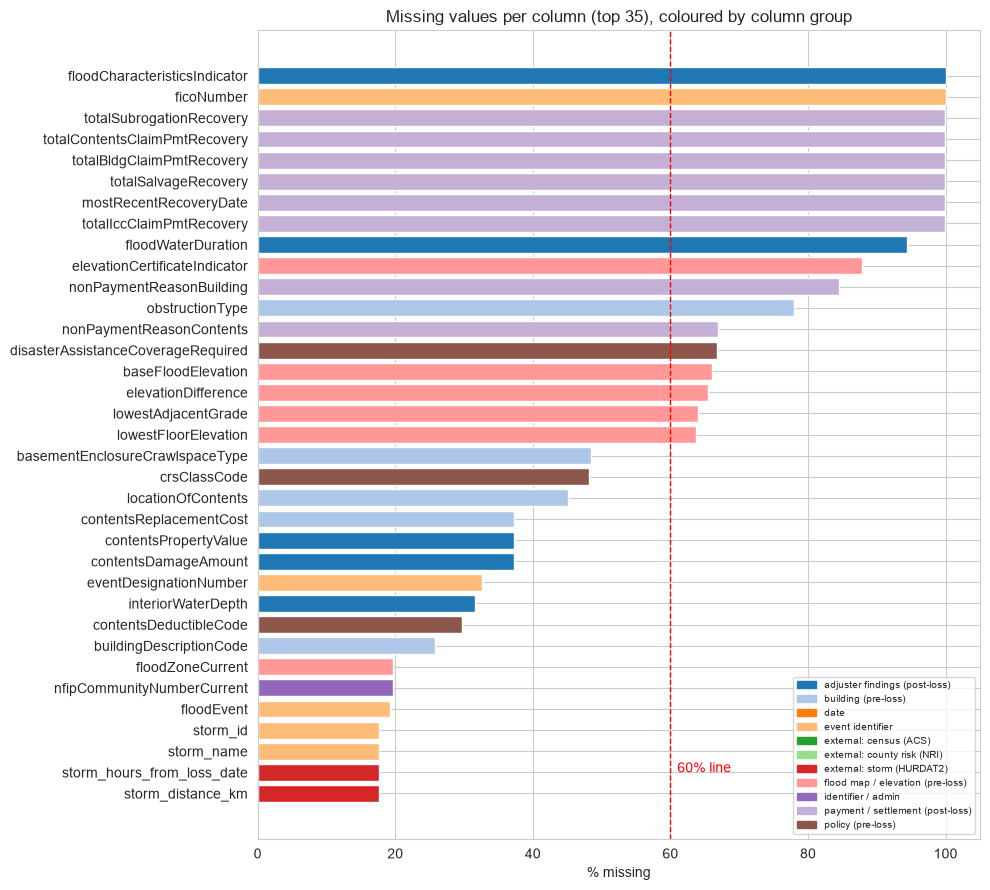

In [13]:
fig, ax = plt.subplots(figsize=(10, 9))
plot_data = missing_table.head(35).iloc[::-1]
group_palette = dict(zip(sorted(missing_table['group'].unique()), sns.color_palette('tab20', missing_table['group'].nunique())))
ax.barh(plot_data.index, plot_data['missing_pct'], color=[group_palette[g] for g in plot_data['group']])
ax.axvline(60, color='red', ls='--', lw=1)
ax.text(61, 1, '60% line', color='red')
ax.set_xlabel('% missing')
ax.set_title('Missing values per column (top 35), coloured by column group')
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in group_palette.values()]
ax.legend(handles, group_palette.keys(), fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_missing_by_column.png', dpi=120)
plt.show()

## 4.2 Missing by year: is the blank random?

Lecture 03 asked: *is the blank information, or was the data really lost?* In NFIP the answer
often depends on **time**. FEMA moved to **Risk Rating 2.0** for new policies on 2021-10-01 and
for renewals on 2022-04-01. The new rating engine (`rateMethod = RE`) does not need an elevation
certificate, so elevation fields stop being collected.

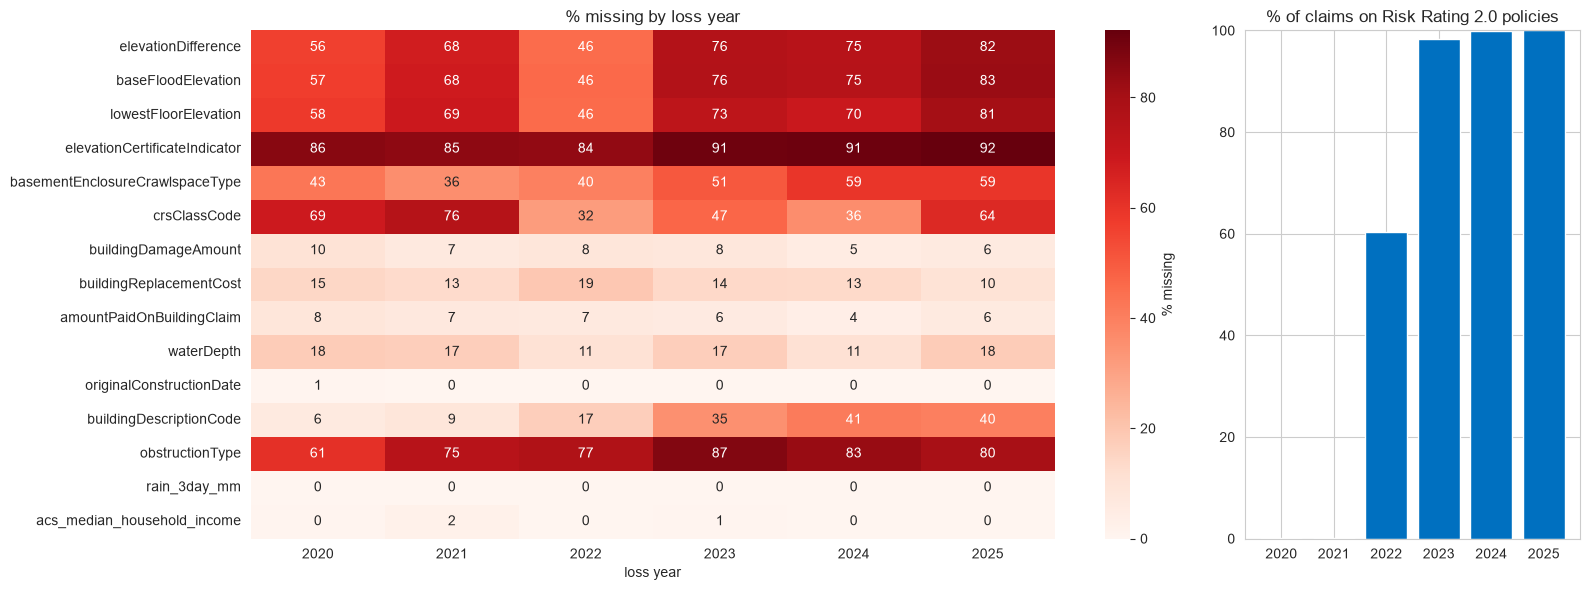

In [14]:
columns_to_track = ['elevationDifference', 'baseFloodElevation', 'lowestFloorElevation', 'elevationCertificateIndicator',
                    'basementEnclosureCrawlspaceType', 'crsClassCode', 'buildingDamageAmount', 'buildingReplacementCost',
                    'amountPaidOnBuildingClaim', 'waterDepth', 'originalConstructionDate', 'buildingDescriptionCode',
                    'obstructionType', 'rain_3day_mm', 'acs_median_household_income']
missing_by_year = claims.groupby('loss_year')[columns_to_track].apply(lambda g: g.isna().mean() * 100).T
missing_by_year['share_RR2_rated (%)'] = np.nan
rr2_share = claims.groupby('loss_year')['rateMethod'].apply(lambda s: (s == 'RE').mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [3, 1]})
sns.heatmap(missing_by_year.drop(columns='share_RR2_rated (%)'), annot=True, fmt='.0f', cmap='Reds', ax=axes[0],
            cbar_kws={'label': '% missing'})
axes[0].set_title('% missing by loss year')
axes[0].set_xlabel('loss year')
axes[1].bar(rr2_share.index.astype(str), rr2_share.values, color='#0070C0')
axes[1].set_title('% of claims on Risk Rating 2.0 policies')
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_missing_by_year.png', dpi=120)
plt.show()

**Reading the heatmap.** Elevation fields are missing for most claims, and the share rises
as Risk Rating 2.0 takes over. The blank is **structural**: it says "this policy was rated by
the new engine", not "the building has no elevation". Imputing a median would hide this.
So for elevation we keep a **flag** (`has_elevation_certificate_data`) and do not trust any
filled value very much.

## 4.3 Missing by state

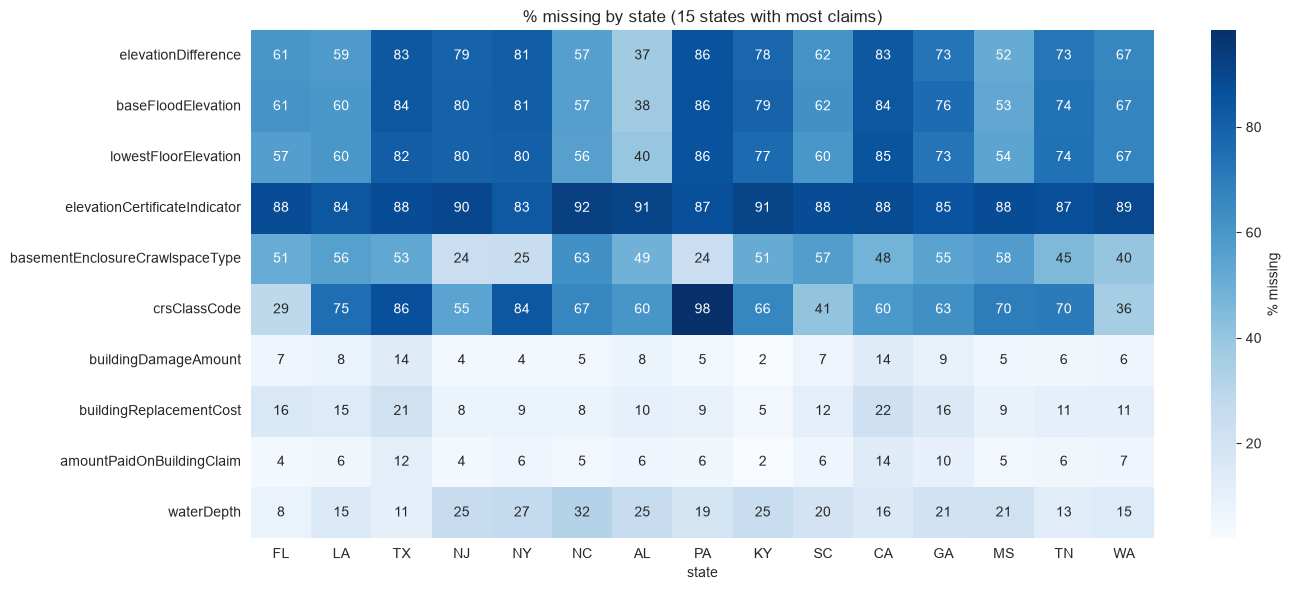

In [15]:
top_states = claims['state'].value_counts().head(15).index
missing_by_state = (claims[claims['state'].isin(top_states)]
                    .groupby('state')[columns_to_track[:10]].apply(lambda g: g.isna().mean() * 100)
                    .loc[top_states])
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(missing_by_state.T, annot=True, fmt='.0f', cmap='Blues', ax=ax, cbar_kws={'label': '% missing'})
ax.set_title('% missing by state (15 states with most claims)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_missing_by_state.png', dpi=120)
plt.show()

## 4.4 The blank IS the information: payments

`amountPaidOnBuildingClaim` is blank for some claims. Is it "unknown", or "nothing was paid"?
We check the non-payment reason on those rows.

In [16]:
blank_payment = claims['amountPaidOnBuildingClaim'].isna()
print(f'Blank building payments: {blank_payment.sum():,}')
print('\nNon-payment reason on those rows (top 6):')
print(claims.loc[blank_payment, 'nonPaymentReasonBuilding'].value_counts(dropna=False).head(6).to_string())
print('\nMedian building damage on those rows:', claims.loc[blank_payment, 'buildingDamageAmount'].median())

Blank building payments: 14,529

Non-payment reason on those rows (top 6):
nonPaymentReasonBuilding
06     4049
NaN    3030
01     2968
97     1887
20     1661
08      562

Median building damage on those rows: 0.0


Most blank payments carry a non-payment reason (for example "06 Not actual flood" or
"01 less than deductible"), and the median damage is 0. So **blank = 0 dollars paid**. This is
exactly the "Pool QC" case from Lecture 03: the blank is the information.

---
# Section 5: Unusual Values and Outliers (Lecture 13)

Lecture 13, Section 1 gave the rule: **an error is fixed or removed; an outlier is kept and
understood.** Floods are heavy-tailed: a few very large losses are real and important.

## 5.1 One column at a time: z-score versus IQR

             method  cut_off_usd  n_flagged  pct_flagged
z-score > 3 (raw $)     535229.0       1583         0.75
   IQR rule (raw $)     236425.0      11490         5.45
 IQR rule (log10 $)    2931493.0         84         0.04


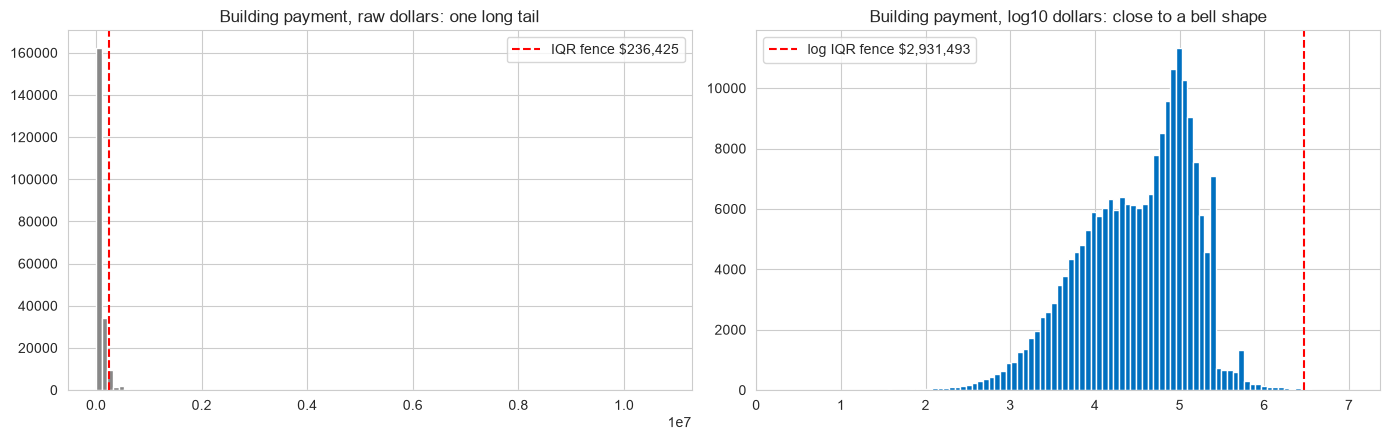

In [17]:
paid_positive = claims.loc[claims['amountPaidOnBuildingClaim'] > 0, 'amountPaidOnBuildingClaim']
log_paid = np.log10(paid_positive)

z_scores = (paid_positive - paid_positive.mean()) / paid_positive.std()
q1, q3 = paid_positive.quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
log_q1, log_q3 = log_paid.quantile([0.25, 0.75])
log_iqr_upper = log_q3 + 1.5 * (log_q3 - log_q1)

outlier_counts = pd.DataFrame({
    'method': ['z-score > 3 (raw $)', 'IQR rule (raw $)', 'IQR rule (log10 $)'],
    'cut_off_usd': [paid_positive.mean() + 3 * paid_positive.std(), iqr_upper, 10 ** log_iqr_upper],
    'n_flagged': [(z_scores > 3).sum(), (paid_positive > iqr_upper).sum(), (log_paid > log_iqr_upper).sum()],
})
outlier_counts['pct_flagged'] = (outlier_counts['n_flagged'] / len(paid_positive) * 100).round(2)
outlier_counts['cut_off_usd'] = outlier_counts['cut_off_usd'].round(0)
print(outlier_counts.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(paid_positive, bins=100, color='#888888')
axes[0].axvline(iqr_upper, color='red', ls='--', label=f'IQR fence ${iqr_upper:,.0f}')
axes[0].set_title('Building payment, raw dollars: one long tail')
axes[0].legend()
axes[1].hist(log_paid, bins=100, color='#0070C0')
axes[1].axvline(log_iqr_upper, color='red', ls='--', label=f'log IQR fence ${10 ** log_iqr_upper:,.0f}')
axes[1].set_title('Building payment, log10 dollars: close to a bell shape')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_payment_distribution.png', dpi=120)
plt.show()

**Reading the result.** On raw dollars the z-score and IQR rules flag thousands of legitimate
large losses, because the 68-95-99.7 rule assumes a bell shape (Lecture 13, 2.2). On the log
scale, almost nothing is flagged. **Decision: keep all large payments, and use log dollars in
models.**

## 5.2 Contextual anomalies: values that are wrong for their context

A value can be normal overall but impossible for its row (Lecture 13, Section 11).

In [18]:
building_age_years = (claims['dateOfLoss'] - claims['originalConstructionDate']).dt.days / 365.25
first_policy_date = pd.to_datetime(claims['originalNBDate'], errors='coerce')
contextual_checks = {
    'payment > damage amount (+1%)': claims['amountPaidOnBuildingClaim'] > 1.01 * claims['buildingDamageAmount'],
    'damage > 3 x replacement cost': claims['buildingDamageAmount'] > 3 * claims['buildingReplacementCost'],
    'coverage > 5 x replacement cost': claims['totalBuildingInsuranceCoverage'] > 5 * claims['buildingReplacementCost'],
    'first policy date after loss date': first_policy_date > claims['dateOfLoss'],
    'loss in zone X but rated V-zone method': (claims['ratedFloodZone'].fillna('').str.startswith('X')) & (claims['rateMethod'] == '4'),
    'post-FIRM flag but built before 1975': (claims['postFIRMConstructionIndicator'] == True) & (claims['originalConstructionDate'].dt.year < 1975),
    'elevated building with a basement': (claims['elevatedBuildingIndicator'] == True) & (claims['basementEnclosureCrawlspaceType'].isin([1, 2])),
}
contextual_table = pd.DataFrame([{'check': name, 'n_rows': int(mask.sum()), 'pct': round(mask.mean() * 100, 3)}
                                 for name, mask in contextual_checks.items()])
contextual_table['decision'] = ['flag; keep (common: payment can include appurtenant structures, debris removal, loss avoidance)',
                                'flag; keep (replacement cost can be outdated)',
                                'flag; keep (multi-unit / condo master policies)',
                                'flag; keep (policy record may be re-written after a transfer)',
                                'no rows / ignore',
                                'flag; keep (substantial improvement can make an old building post-FIRM)',
                                'flag; keep (enclosure codes overlap)']
contextual_table.to_csv(TABLE_DIR / '01_contextual_anomalies.csv', index=False)
print(contextual_table.to_string(index=False))
claims['flag_payment_above_damage'] = contextual_checks['payment > damage amount (+1%)'].astype(int)

                                 check  n_rows    pct                                                                                        decision
         payment > damage amount (+1%)   49078 19.389 flag; keep (common: payment can include appurtenant structures, debris removal, loss avoidance)
         damage > 3 x replacement cost      64  0.025                                                   flag; keep (replacement cost can be outdated)
       coverage > 5 x replacement cost     283  0.112                                                 flag; keep (multi-unit / condo master policies)
     first policy date after loss date    2327  0.919                                   flag; keep (policy record may be re-written after a transfer)
loss in zone X but rated V-zone method       0  0.000                                                                                no rows / ignore
  post-FIRM flag but built before 1975     961  0.380                         flag; keep (substantia

These rows look strange, but each has a plausible business reason. We **flag** them and keep them.
Removing them would remove real, if messy, insurance history.

## 5.3 Many columns together: Isolation Forest

Lecture 13, Section 4: "one column is not enough". A $250k coverage is normal, and a 1-floor house
is normal, but a $250k payment on a $40k mobile home is not. Isolation Forest isolates points
with random splits. Unusual points are isolated in few splits, so they get a short path and a
high anomaly score.

In [19]:
anomaly_features = pd.DataFrame({
    'log_coverage': np.log1p(claims['totalBuildingInsuranceCoverage']),
    'log_replacement_cost': np.log1p(claims['buildingReplacementCost']),
    'log_paid': np.log1p(claims['amountPaidOnBuildingClaim'].fillna(0)),
    'log_damage': np.log1p(claims['buildingDamageAmount']),
    'paid_to_coverage': claims['amountPaidOnBuildingClaim'].fillna(0) / claims['totalBuildingInsuranceCoverage'],
    'building_age': building_age_years,
}).dropna()
isolation_forest = IsolationForest(n_estimators=200, contamination=0.01, random_state=SEED)
anomaly_label = isolation_forest.fit_predict(StandardScaler().fit_transform(anomaly_features))
anomaly_features['is_anomaly'] = (anomaly_label == -1).astype(int)
print(f'Rows scored: {len(anomaly_features):,}   flagged as anomalies (1%): {anomaly_features["is_anomaly"].sum():,}')
print('\nMedian profile, normal vs anomaly:')
print(anomaly_features.groupby('is_anomaly').median().round(3).T.to_string())
claims['flag_isolation_forest_anomaly'] = 0
claims.loc[anomaly_features.index, 'flag_isolation_forest_anomaly'] = anomaly_features['is_anomaly']

Rows scored: 215,483   flagged as anomalies (1%): 2,155

Median profile, normal vs anomaly:
is_anomaly                 0       1
log_coverage          12.429  15.406
log_replacement_cost  12.586  16.194
log_paid              10.336  11.183
log_damage            10.421  11.308
paid_to_coverage       0.169   0.006
building_age          49.572  41.739


**Reading the profile.** The anomalies are mostly **large commercial and condominium master policies**:
coverage and replacement cost are about 20 times the typical claim, while the payment is a tiny share of
the coverage. They are real, just rare. They are kept, and the flag is saved so later notebooks can test
whether results change without them.

**Note on "payment > damage" (19% of rows).** This is too common to be an error. `buildingDamageAmount`
is damage to the main building, while the building payment can also include appurtenant structures,
debris removal and loss-avoidance costs. It is a documented quirk of the file, so we only flag it.

---
# Section 6: Column-Level Decisions: What We Drop

Lecture 03, 2.1: dropping a column costs information. We drop a column only for a clear reason.

In [20]:
drop_decisions = [
    ('id', 'identifier: unique per row, no meaning'),
    ('ficoNumber', '100% missing in 2020-2025'),
    ('disasterAssistanceCoverageRequired', '67% missing; not related to the flood or the building'),
    ('asOfDate', 'admin: date FEMA exported the file, same for all rows'),
    ('yearOfLoss', 'redundant: same as year of dateOfLoss'),
    ('preFirmIndicator', 'redundant: the opposite of postFIRMConstructionIndicator'),
    ('nfipCommunityNumberCurrent', 'redundant with nfipRatedCommunityNumber, and it is the current value (time travel)'),
    ('nfipCommunityName', 'free text; location is already in state/county/lat/lon'),
    ('reportedCity', 'free text; location is already in state/county/lat/lon'),
    ('floodCharacteristicsIndicator', '100% missing'),
    ('floodWaterDuration', '>90% missing, and it is an adjuster finding (post-loss)'),
    ('agricultureStructureIndicator', 'near-constant (almost all False)'),
    ('houseWorship', 'near-constant (almost all False)'),
    ('nonProfitIndicator', 'near-constant (almost all False)'),
    ('stateOwnedIndicator', 'near-constant (almost all False)'),
    ('smallBusinessIndicatorBuilding', 'near-constant (almost all False)'),
    ('baseFloodElevation', '>60% missing after placeholders; absolute height in feet is not comparable across places'),
    ('lowestFloorElevation', '>60% missing; absolute height; the useful part is in elevationDifference'),
    ('lowestAdjacentGrade', '>60% missing; absolute height; the useful part is in elevationDifference'),
    ('obstructionType', '>75% missing; not reported for RR2.0 policies'),
    ('buildingDescriptionCode', 'redundant with occupancyType and condominiumCoverageTypeCode'),
    ('locationOfContents', 'contents only; this project studies the building'),
    ('contentsDeductibleCode', 'contents only'),
    ('contentsReplacementCost', 'contents only'),
    ('mostRecentRecoveryDate', 'settlement admin, post-loss'),
    ('totalSalvageRecovery', 'settlement admin, post-loss'),
    ('totalBldgClaimPmtRecovery', 'settlement admin, post-loss'),
    ('totalContentsClaimPmtRecovery', 'settlement admin, post-loss'),
    ('totalIccClaimPmtRecovery', 'settlement admin, post-loss'),
    ('totalSubrogationRecovery', 'settlement admin, post-loss'),
]
drop_table = pd.DataFrame(drop_decisions, columns=['column', 'reason'])
drop_table['missing_pct'] = [round(claims[c].isna().mean() * 100, 1) if c in claims.columns else np.nan for c in drop_table['column']]
drop_table['most_common_value_share_pct'] = [
    round(claims[c].value_counts(normalize=True, dropna=False).iloc[0] * 100, 1) if c in claims.columns else np.nan
    for c in drop_table['column']]
drop_table.to_csv(TABLE_DIR / '01_dropped_columns.csv', index=False)
print(f'Columns dropped: {len(drop_table)}')
print(drop_table.to_string(index=False))

Columns dropped: 30
                            column                                                                                   reason  missing_pct  most_common_value_share_pct
                                id                                                   identifier: unique per row, no meaning          0.0                          0.0
                        ficoNumber                                                                100% missing in 2020-2025        100.0                        100.0
disasterAssistanceCoverageRequired                                    67% missing; not related to the flood or the building         66.7                         66.7
                          asOfDate                                    admin: date FEMA exported the file, same for all rows          0.0                        100.0
                        yearOfLoss                                                    redundant: same as year of dateOfLoss          0.0              

Notice what we **do not** drop here: damage amounts, payments, water depth and cause of damage.
They are needed as **targets** or for checking, even though they must never be **features**
(see the leakage section). We also keep `id` in the saved file for joins, but it is never a feature.

In [21]:
claims = claims.drop(columns=[c for c in drop_table['column'] if c != 'id' and c in claims.columns])
print('Columns left:', claims.shape[1])

Columns left: 92


---
# Section 7: Making Data Usable: Recoding and New Features

Lecture 03, Sections 4-6: discretization, encoding (nominal vs ordinal) and transformation.

## 7.1 Codes into readable categories

In [22]:
OCCUPANCY_GROUPS = {
    1: 'single_family', 11: 'single_family',
    2: 'multi_family_2to4', 12: 'multi_family_2to4',
    3: 'multi_family_5plus', 13: 'multi_family_5plus',
    14: 'mobile_home',
    15: 'condo_association', 16: 'unit_in_multi_unit_building',
    4: 'non_residential', 6: 'non_residential', 17: 'non_residential', 18: 'non_residential', 19: 'non_residential',
}
claims['occupancy_group'] = claims['occupancyType'].map(OCCUPANCY_GROUPS).fillna('other')


def flood_zone_group(zone):
    if pd.isna(zone) or zone == '':
        return 'unknown'
    zone = str(zone).upper()
    if zone.startswith('V'):
        return 'V_coastal_high_hazard'
    if zone.startswith('A99') or zone.startswith('AR'):
        return 'A_protected_by_levee'
    if zone.startswith('A'):
        return 'A_special_flood_hazard'
    if zone in ('X', 'B', 'C') or zone.startswith('X'):
        return 'X_moderate_or_minimal'
    if zone.startswith('D'):
        return 'D_undetermined'
    return 'unknown'


claims['flood_zone_group'] = claims['ratedFloodZone'].map(flood_zone_group)
claims['in_special_flood_hazard_area'] = claims['flood_zone_group'].isin(['V_coastal_high_hazard', 'A_special_flood_hazard']).astype(int)

DEDUCTIBLE_DOLLARS = {'0': 500, '1': 1000, '2': 2000, '3': 3000, '4': 4000, '5': 5000, '9': 750, 'A': 10000,
                      'B': 15000, 'C': 20000, 'D': 25000, 'E': 50000, 'F': 1250, 'G': 1500, 'H': 200}
claims['building_deductible_usd'] = claims['buildingDeductibleCode'].map(DEDUCTIBLE_DOLLARS)

FOUNDATION_NAMES = {'0': 'unknown', '1': 'slab', '2': 'basement', '3': 'crawlspace', '4': 'elevated_open_piles',
                    '5': 'elevated_enclosed_piles', '6': 'elevated_enclosed_walls'}
claims['foundation_group'] = claims['foundationType'].map(FOUNDATION_NAMES).fillna('unknown')

FLOORS_NAMES = {1: 'one_floor', 2: 'two_floors', 3: 'three_plus_floors', 4: 'split_level',
                5: 'manufactured_home', 6: 'townhouse_3plus'}
claims['floors_group'] = claims['numberOfFloorsInTheInsuredBuilding'].map(FLOORS_NAMES)

claims['rated_by_risk_rating_2'] = (claims['rateMethod'] == 'RE').astype(int)
for column in ['elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator',
               'rentalPropertyIndicator', 'floodproofedIndicator']:
    claims[column] = claims[column].astype('float').fillna(0).astype(int)

print(claims['occupancy_group'].value_counts().to_string())
print()
print(claims['flood_zone_group'].value_counts().to_string())

occupancy_group
single_family                  198821
non_residential                 17055
multi_family_2to4               11455
condo_association               10451
multi_family_5plus               6857
mobile_home                      4876
unit_in_multi_unit_building      3609

flood_zone_group
A_special_flood_hazard    196161
X_moderate_or_minimal      46166
V_coastal_high_hazard       9824
A_protected_by_levee         877
unknown                       51
D_undetermined                45


## 7.2 New numeric features

In [23]:
claims['building_age_at_loss'] = (claims['dateOfLoss'] - claims['originalConstructionDate']).dt.days / 365.25
claims['policy_tenure_years'] = ((claims['dateOfLoss'] - pd.to_datetime(claims['originalNBDate'], errors='coerce'))
                                 .dt.days / 365.25).clip(lower=0)
claims['loss_month'] = claims['dateOfLoss'].dt.month
claims['hurricane_season'] = claims['loss_month'].between(6, 11).astype(int)
claims['log_building_coverage'] = np.log1p(claims['totalBuildingInsuranceCoverage'])
claims['log_contents_coverage'] = np.log1p(claims['totalContentsInsuranceCoverage'].fillna(0))
claims['has_contents_coverage'] = (claims['totalContentsInsuranceCoverage'].fillna(0) > 0).astype(int)
claims['has_elevation_certificate_data'] = claims['elevationDifference'].notna().astype(int)

# Lecture 03, 4.2: discretize year built into eras that mean something in flood policy
era_bins = [0, 1974, 1990, 2010, 2100]
era_labels = ['pre_1975_before_most_FIRMs', '1975_1990_early_FIRM', '1991_2010', 'after_2010']
claims['construction_era'] = pd.cut(claims['originalConstructionDate'].dt.year, bins=era_bins, labels=era_labels).astype('object')
print(claims[['building_age_at_loss', 'policy_tenure_years', 'log_building_coverage']].describe().round(2).to_string())

       building_age_at_loss  policy_tenure_years  log_building_coverage
count             252614.00            249614.00              253124.00
mean                  48.29                 8.31                  12.25
std                   23.00                 7.38                   0.81
min                    0.00                 0.00                   4.62
25%                   33.41                 2.19                  12.06
50%                   48.74                 6.30                  12.43
75%                   61.77                12.59                  12.43
max                  225.74                57.33                  19.31


---
# Section 8: Imputation, Column by Column

Every rule below is learned from the **training years (2020-2023)** and applied to all rows, with two
honest notes:

1. **Rain is the exception.** The rain fill (rule 8) uses the median of claims in the **same state on the same
   loss date, across all years** (so test-year rows are included). This is a same-day fill from nearby claims of
   the same storm, not a learned statistic, and it contains no outcome information. Very few claims need it
   (points on water or at the edge of the grid; see the imputation log).
2. **Imputation happens before the event-grouped cross-validation.** The training-year medians are computed on
   all of 2020-2023, so inside the CV each validation fold has seen medians that partly come from its own events.
   A median of more than 100,000 rows hardly moves when one event is removed, so the effect is tiny. The main
   2024-2025 test is not affected at all.

Each imputed column also gets a `_was_missing` flag, so a model can learn if "missing" itself
carries signal (as it does for elevation).

In [24]:
imputation_log = []
train_rows = claims['is_train_period']


def record_imputation(column, n_imputed, method, value_text):
    imputation_log.append({'column': column, 'n_imputed': int(n_imputed),
                           'pct_imputed': round(n_imputed / len(claims) * 100, 2),
                           'method': method, 'value_used': value_text})


# --- 1. Payments: blank means 0 (Section 4.4) ---
for column in ['amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim', 'amountPaidOnIncreasedCostOfComplianceClaim']:
    n_missing = claims[column].isna().sum()
    claims[column] = claims[column].fillna(0)
    record_imputation(column, n_missing, 'domain rule: blank = nothing paid', '0')

# --- 2. CRS class: blank means the community is not in the CRS program, i.e. class 10 (no discount) ---
n_missing = claims['crsClassCode'].isna().sum()
claims['crsClassCode'] = claims['crsClassCode'].fillna(10)
record_imputation('crsClassCode', n_missing, 'domain rule: not in CRS = class 10', '10')

# --- 3. Categorical building fields: group mode or explicit "not_reported" ---
n_missing = claims['basementEnclosureCrawlspaceType'].isna().sum()
claims['basement_group'] = claims['basementEnclosureCrawlspaceType'].map(
    {0: 'none', 1: 'finished_basement', 2: 'unfinished_basement', 3: 'crawlspace', 4: 'subgrade_crawlspace'}).fillna('not_reported')
record_imputation('basementEnclosureCrawlspaceType', n_missing, 'new category (blank is structural under RR2.0)', "'not_reported'")

floors_mode_by_occupancy = claims[train_rows].groupby('occupancy_group')['floors_group'].agg(lambda s: s.mode().iloc[0] if s.notna().any() else 'one_floor')
n_missing = claims['floors_group'].isna().sum()
claims['floors_group'] = claims['floors_group'].fillna(claims['occupancy_group'].map(floors_mode_by_occupancy))
record_imputation('numberOfFloorsInTheInsuredBuilding', n_missing, 'mode within occupancy group (train years)',
                  '; '.join(f'{k}={v}' for k, v in floors_mode_by_occupancy.items()))

deductible_mode_by_occupancy = claims[train_rows].groupby('occupancy_group')['building_deductible_usd'].agg(lambda s: s.mode().iloc[0])
n_missing = claims['building_deductible_usd'].isna().sum()
claims['building_deductible_usd'] = claims['building_deductible_usd'].fillna(claims['occupancy_group'].map(deductible_mode_by_occupancy))
record_imputation('buildingDeductibleCode', n_missing, 'mode within occupancy group (train years)',
                  '; '.join(f'{k}=${v:,.0f}' for k, v in deductible_mode_by_occupancy.items()))

In [25]:
# --- 4. Replacement cost: median within occupancy group x state (train years), then occupancy median ---
claims['replacement_cost_was_missing'] = claims['buildingReplacementCost'].isna().astype(int)
median_cost_occ_state = claims[train_rows].groupby(['occupancy_group', 'state'])['buildingReplacementCost'].median()
median_cost_occ = claims[train_rows].groupby('occupancy_group')['buildingReplacementCost'].median()
n_missing = claims['buildingReplacementCost'].isna().sum()
fill_values = pd.Series(list(zip(claims['occupancy_group'], claims['state'])), index=claims.index).map(median_cost_occ_state)
fill_values = fill_values.fillna(claims['occupancy_group'].map(median_cost_occ))
claims['buildingReplacementCost'] = claims['buildingReplacementCost'].fillna(fill_values)
record_imputation('buildingReplacementCost', n_missing, 'median by occupancy group x state, fallback occupancy (train years)',
                  f'e.g. single_family overall median ${median_cost_occ.get("single_family", np.nan):,.0f}')
claims['log_replacement_cost'] = np.log1p(claims['buildingReplacementCost'])
claims['coverage_to_replacement_ratio'] = (claims['totalBuildingInsuranceCoverage'] / claims['buildingReplacementCost']).clip(0, 5)

**Construction year with k-NN imputation (Lecture 03).** Old neighbourhoods have old houses.
So a building with no construction date is likely as old as its neighbours. We use `KNNImputer`
with latitude, longitude and the ACS median year built of the block group. To keep it fast and
leakage-free, the neighbours come from a 40,000-row sample of the **training years**.

In [26]:
claims['construction_year'] = claims['originalConstructionDate'].dt.year
claims['construction_year_was_missing'] = claims['construction_year'].isna().astype(int)
knn_columns = ['latitude', 'longitude', 'acs_median_year_built', 'construction_year']
reference_rows = claims[train_rows & claims['construction_year'].notna() & claims['acs_median_year_built'].notna()]
reference_rows = reference_rows.sample(min(40_000, len(reference_rows)), random_state=SEED)
rows_to_fill = claims[claims['construction_year'].isna()]
knn_input = pd.concat([reference_rows[knn_columns], rows_to_fill[knn_columns]])
knn_input['acs_median_year_built'] = knn_input['acs_median_year_built'].fillna(reference_rows['acs_median_year_built'].median())
knn_scaler = StandardScaler().fit(reference_rows[knn_columns])
knn_imputer = KNNImputer(n_neighbors=5)
knn_imputer.fit(knn_scaler.transform(reference_rows[knn_columns]))
filled = knn_scaler.inverse_transform(knn_imputer.transform(knn_scaler.transform(rows_to_fill[knn_columns].fillna(
    {'acs_median_year_built': reference_rows['acs_median_year_built'].median()}))))
claims.loc[rows_to_fill.index, 'construction_year'] = np.round(filled[:, 3])
record_imputation('originalConstructionDate (year)', len(rows_to_fill), 'KNNImputer k=5 on lat, lon, ACS median year built',
                  f'median filled year {np.median(filled[:, 3]):.0f}')
claims['building_age_at_loss'] = claims['building_age_at_loss'].fillna(claims['loss_year'] - claims['construction_year'])
claims['construction_era'] = claims['construction_era'].fillna(
    pd.cut(claims['construction_year'], bins=era_bins, labels=era_labels).astype('object'))
print(f'Filled {len(rows_to_fill):,} construction years. Filled-year summary:')
print(pd.Series(filled[:, 3]).describe().round(0).to_string())

Filled 510 construction years. Filled-year summary:
count     510.0
mean     1976.0
std        18.0
min      1916.0
25%      1964.0
50%      1977.0
75%      1989.0
max      2010.0


In [27]:
# --- 5. Elevation difference: keep a flag, fill with median by flood zone group (train years) ---
median_elevation_by_zone = claims[train_rows].groupby('flood_zone_group')['elevationDifference'].median()
overall_median_elevation = claims.loc[train_rows, 'elevationDifference'].median()
n_missing = claims['elevationDifference'].isna().sum()
claims['elevationDifference'] = claims['elevationDifference'].fillna(
    claims['flood_zone_group'].map(median_elevation_by_zone)).fillna(overall_median_elevation)
record_imputation('elevationDifference', n_missing, 'median by flood zone group (train) + flag has_elevation_certificate_data',
                  '; '.join(f'{k}={v:g} ft' for k, v in median_elevation_by_zone.dropna().items()))

# --- 6. Policy tenure ---
n_missing = claims['policy_tenure_years'].isna().sum()
median_tenure = claims.loc[train_rows, 'policy_tenure_years'].median()
claims['policy_tenure_years'] = claims['policy_tenure_years'].fillna(median_tenure)
record_imputation('policy_tenure_years (from originalNBDate)', n_missing, 'median (train years)', f'{median_tenure:.1f} years')

# --- 7. numberOfUnits ---
n_missing = claims['numberOfUnits'].isna().sum()
claims['numberOfUnits'] = claims['numberOfUnits'].fillna(1).clip(lower=1)
record_imputation('numberOfUnits', n_missing, 'domain rule: at least one unit', '1')

In [28]:
# --- 8. External: rain ---
rain_columns = ['rain_loss_day_mm', 'rain_3day_mm', 'rain_7day_mm', 'rain_max_daily_7day_mm']
for column in rain_columns:
    n_missing = claims[column].isna().sum()
    event_state_median = claims.groupby(['floodEvent', 'state'])[column].transform('median')
    state_date_median = claims.groupby(['state', 'dateOfLoss'])[column].transform('median')
    claims[column] = claims[column].fillna(state_date_median).fillna(event_state_median).fillna(0)
    record_imputation(column, n_missing, 'median of claims in same state and loss date (all years), then same event, then 0',
                      'point fell on water / grid edge')

# --- 9. External: storm. No storm in the +/- 3 day window is a real answer, not a missing value ---
claims['no_storm_within_window'] = claims['storm_distance_km'].isna().astype(int)
n_missing = claims['storm_distance_km'].isna().sum()
claims['storm_distance_km'] = claims['storm_distance_km'].fillna(2000).clip(upper=2000)
claims['storm_wind_at_closest_kt'] = claims['storm_wind_at_closest_kt'].fillna(0)
claims['storm_lifetime_max_wind_kt'] = claims['storm_lifetime_max_wind_kt'].fillna(0)
claims['storm_category_at_closest'] = claims['storm_category_at_closest'].fillna(-2)
claims['storm_hours_from_loss_date'] = claims['storm_hours_from_loss_date'].fillna(0)
record_imputation('storm_* (HURDAT2)', n_missing, 'no storm within +/-3 days: distance capped at 2,000 km, wind 0, category -2',
                  'plus flag no_storm_within_window')
# wind felt at the claim: a simple decay of wind with distance (Rankine-like, radius of max wind ~ 50 km)
claims['storm_wind_proxy_at_claim_kt'] = claims['storm_wind_at_closest_kt'] * np.minimum(1.0, (50 / claims['storm_distance_km'].clip(lower=1)) ** 0.6)

# --- 10a. NRI coastal and hurricane scores are blank for counties where FEMA models no such hazard ---
#          (inland counties have no coastal flooding). Blank here means "no risk", so 0 is the honest value.
for column in ['nri_coastal_flood_risk_score', 'nri_coastal_flood_annual_frequency', 'nri_hurricane_risk_score']:
    n_missing = claims[column].isna().sum()
    has_county_match = claims['nri_overall_risk_score'].notna()
    claims.loc[has_county_match, column] = claims.loc[has_county_match, column].fillna(0)
    record_imputation(column, n_missing - claims[column].isna().sum(), 'domain rule: hazard not modelled for county = 0', '0')

# --- 10b. External: ACS and NRI: state median (train years) ---
external_context_columns = [c for c in claims.columns if c.startswith('acs_') and c != 'acs_join_level'] + \
                           [c for c in claims.columns if c.startswith('nri_')]
for column in external_context_columns:
    n_missing = claims[column].isna().sum()
    if n_missing == 0:
        continue
    state_median = claims[train_rows].groupby('state')[column].median()
    claims[column] = claims[column].fillna(claims['state'].map(state_median)).fillna(claims.loc[train_rows, column].median())
    record_imputation(column, n_missing, 'state median (train years)', 'varies by state')

imputation_table = pd.DataFrame(imputation_log)
imputation_table.to_csv(TABLE_DIR / '01_imputation_log.csv', index=False)
print(imputation_table.to_string(index=False))

                                    column  n_imputed  pct_imputed                                                                            method                                                                                                                                                                                                          value_used
                 amountPaidOnBuildingClaim      14529         5.74                                                 domain rule: blank = nothing paid                                                                                                                                                                                                                   0
                 amountPaidOnContentsClaim      14529         5.74                                                 domain rule: blank = nothing paid                                                                                                                                  

**What we did NOT impute, on purpose**

| Column | Why it stays missing |
|---|---|
| `buildingDamageAmount` | it is the **target** of RQ2. Lecture rule: never impute the target. RQ2 uses only rows where it is recorded. |
| `waterDepth`, `interior/exteriorWaterDepth` | adjuster findings, used only for checking, never as features |
| `causeOfDamage` | the **target** of RQ5; rows without it are left out of RQ5 |
| `buildingPropertyValue` | adjuster's estimate after the loss; used only to define damage ratios |

---
# Section 9: LEAKAGE: Features That Must Never Be Used

Lecture 07, Section 11 gave four ways leakage happens:
1. a column derived from the target, 2. preprocessing before the split,
3. tuning on the test set, 4. **time travel** (information that did not exist at prediction time).

Our prediction moment is: **"a claim has just been filed after a known storm"**. At that moment we
know the building, the policy, the place and the weather. We do **not** know what the adjuster
will find or what will be paid.

In [29]:
leakage_rows = [
    ('amountPaidOnBuildingClaim', 'payment', 'IS the RQ1 target (paid > 0). Also near-equal to damage minus deductible', 'RQ1-RQ6 (target only)'),
    ('netBuildingPaymentAmount', 'payment', 'building payment after adjustments: same information as the target', 'all'),
    ('buildingDamageAmount', 'adjuster', 'IS the RQ2 target; payment = damage - deductible, capped by coverage (type 1)', 'all (target of RQ2)'),
    ('contentsDamageAmount', 'adjuster', 'measured in the same inspection; strongly correlated with building damage', 'all'),
    ('amountPaidOnContentsClaim / netContentsPaymentAmount', 'payment', 'paid at the same time; a paid contents claim means there was a flood inside', 'all'),
    ('amountPaidOnIncreasedCostOfComplianceClaim / netIccPaymentAmount', 'payment', 'ICC is paid only after a building is declared substantially damaged', 'all'),
    ('nonPaymentReasonBuilding', 'payment', 'not null exactly when the building is not paid: a perfect leak for RQ1', 'all'),
    ('nonPaymentReasonContents', 'payment', 'shares the reason with the building in most claims', 'all'),
    ('buildingPropertyValue', 'adjuster', 'actual cash value estimated by the adjuster during the claim (time travel)', 'all features; used only to build damage ratio'),
    ('contentsPropertyValue', 'adjuster', 'adjuster estimate, post-loss', 'all'),
    ('waterDepth / exteriorWaterDepth / interiorWaterDepth', 'adjuster', 'measured at inspection after the flood; depth drives damage almost directly', 'all (used only as a check)'),
    ('floodWaterDuration', 'adjuster', 'post-loss inspection; also 94% missing (dropped)', 'all'),
    ('causeOfDamage', 'adjuster', 'chosen by the adjuster after inspection; target of RQ5', 'RQ1-RQ4, RQ6 features; RQ5 target'),
    ('flag_payment_above_damage', 'derived', 'built from payment and damage', 'all'),
    ('openDate / mostRecentPaymentDate', 'settlement', 'claim processing dates: a fast payment date means a paid claim', 'all'),
    ('floodZoneCurrent', 'map', 'zone on TODAY\'s map, not the map at loss time (time travel). We use ratedFloodZone', 'all'),
    ('floodEvent / eventDesignationNumber / ficoNumber / storm_name', 'event id', 'not a leak by itself, but lets a model memorise one storm; used only to GROUP the cross-validation', 'all features'),
    ('large_loss / damage ratio targets', 'derived', 'target definitions built from damage', 'all features'),
    ('buildingReplacementCost (+ log, coverage ratio, missing flag)', 'hidden (missingness)',
     'filled in during claim adjustment: missing for 15% of claims, and those are paid far less often (Section 9.2)', 'all features'),
]
leakage_table = pd.DataFrame(leakage_rows, columns=['feature', 'kind', 'why it leaks', 'excluded from'])
leakage_table.to_csv(TABLE_DIR / '01_leakage_table.csv', index=False)
print(leakage_table.to_string(index=False))

                                                         feature                 kind                                                                                                  why it leaks                                 excluded from
                                       amountPaidOnBuildingClaim              payment                                      IS the RQ1 target (paid > 0). Also near-equal to damage minus deductible                         RQ1-RQ6 (target only)
                                        netBuildingPaymentAmount              payment                                            building payment after adjustments: same information as the target                                           all
                                            buildingDamageAmount             adjuster                                 IS the RQ2 target; payment = damage - deductible, capped by coverage (type 1)                           all (target of RQ2)
                                

**A softer timing issue: `storm_lifetime_max_wind_kt`.** This feature is the storm's strongest wind over its
**whole life**. If a claim's loss date is *before* the storm reached its peak, this value was not known yet on that
day. It is not an outcome leak (it says nothing about the house), so we keep it. But it fits the prediction moment
"a claim filed **after** a known storm" (post-event triage), not a forecast made while the storm is still coming.
The other storm features (distance, wind and category **at the closest point**) do not have this problem.

## 9.1 Proof that the leak is real

If we use a leaking column, the model looks brilliant. Lecture 07: *"if your accuracy is
suspiciously high, look for leakage. Do not celebrate."* Here is the AUC of single columns
for RQ1 (building paid > 0) on the training years.

In [30]:
from sklearn.metrics import roc_auc_score

building_paid_flag = (claims['amountPaidOnBuildingClaim'] > 0).astype(int)
single_column_auc = {
    'buildingDamageAmount (LEAK)': claims['buildingDamageAmount'].fillna(0),
    'nonPaymentReasonBuilding is blank (LEAK)': claims['nonPaymentReasonBuilding'].isna().astype(int),
    'amountPaidOnContentsClaim (LEAK)': claims['amountPaidOnContentsClaim'],
    'waterDepth (LEAK)': claims['waterDepth'].fillna(0),
    'rain_3day_mm (allowed)': claims['rain_3day_mm'],
    'storm_wind_proxy_at_claim_kt (allowed)': claims['storm_wind_proxy_at_claim_kt'],
    'log_building_coverage (allowed)': claims['log_building_coverage'],
    'elevationDifference (allowed)': -claims['elevationDifference'],
}
auc_rows = [{'feature': name, 'single_feature_AUC': round(roc_auc_score(building_paid_flag[train_rows], values[train_rows]), 3)}
            for name, values in single_column_auc.items()]
print(pd.DataFrame(auc_rows).to_string(index=False))

                                 feature  single_feature_AUC
             buildingDamageAmount (LEAK)               0.969
nonPaymentReasonBuilding is blank (LEAK)               0.964
        amountPaidOnContentsClaim (LEAK)               0.665
                       waterDepth (LEAK)               0.641
                  rain_3day_mm (allowed)               0.571
  storm_wind_proxy_at_claim_kt (allowed)               0.509
         log_building_coverage (allowed)               0.503
           elevationDifference (allowed)               0.580


## 9.2 A hidden leak: when "missing" knows the answer

Lecture 03 taught that a blank can carry information. Here that is dangerous. A column that looks like a
pre-loss building fact can still leak, if it is **filled in during the claim**. Then *whether it is blank*
tells the model if an adjuster completed the file. We test every candidate column: is the paid rate
different when the column is blank?

In [31]:
merged_raw = pd.read_parquet(PROCESSED_DIR / 'claims_merged_2020_2025.parquet',
                             columns=['id', 'buildingReplacementCost', 'crsClassCode', 'basementEnclosureCrawlspaceType',
                                      'elevationDifference', 'originalConstructionDate', 'buildingDescriptionCode',
                                      'contentsReplacementCost', 'locationOfContents', 'obstructionType'])
merged_raw = merged_raw[merged_raw['id'].isin(claims['id'])].set_index('id').loc[claims['id']]
missingness_rows = []
for column in merged_raw.columns:
    blank = merged_raw[column].isna().values
    if column == 'buildingReplacementCost':
        blank = blank | (merged_raw[column].fillna(0) <= 0).values
    missingness_rows.append({'column': column, 'blank_%': blank.mean() * 100,
                             'paid_rate_when_blank_%': building_paid_flag[blank].mean() * 100,
                             'paid_rate_when_present_%': building_paid_flag[~blank].mean() * 100})
missingness_table = pd.DataFrame(missingness_rows)
missingness_table['gap_points'] = missingness_table['paid_rate_when_present_%'] - missingness_table['paid_rate_when_blank_%']
missingness_table = missingness_table.sort_values('gap_points', ascending=False).round(1)
missingness_table.to_csv(TABLE_DIR / '01_missingness_leakage_check.csv', index=False)
print(missingness_table.to_string(index=False))
print('\nSingle-feature AUC of "replacement cost is blank" for RQ1:',
      round(roc_auc_score(building_paid_flag, 1 - claims['replacement_cost_was_missing']), 3))

                         column  blank_%  paid_rate_when_blank_%  paid_rate_when_present_%  gap_points
        buildingReplacementCost     14.7                    34.8                      91.6        56.7
        contentsReplacementCost     37.2                    73.4                      89.1        15.7
       originalConstructionDate      0.1                    74.6                      83.2         8.6
                   crsClassCode     48.1                    81.6                      84.8         3.2
                obstructionType     77.9                    83.1                      83.9         0.8
basementEnclosureCrawlspaceType     48.5                    83.8                      82.7        -1.0
        buildingDescriptionCode     25.8                    84.4                      82.8        -1.6
             locationOfContents     45.1                    84.2                      82.5        -1.7
            elevationDifference     65.5                    84.2         

**Finding.** `buildingReplacementCost` is blank (or 0) for about 15% of claims, and those claims are paid far
less often than the rest. The other columns show small gaps that are explained by policy type, not by the
claim process. `contentsReplacementCost` also has a gap, but it is a contents field and is already dropped.
So the replacement cost behaves like an **adjuster field**, even though the data dictionary says "reported by
the insurer". We remove it, its log, the coverage-to-replacement ratio and its missing flag from all feature
lists. Notebook 04 shows, as a sensitivity test only, how much it would add if one accepted it as pre-loss.

The leaking columns alone reach AUC close to 1.0. The honest, pre-loss columns are far weaker.
Every result in this project uses only the honest columns.

---
# Section 10: Targets for the Research Questions

- **RQ1:** `building_paid_flag` = 1 if `amountPaidOnBuildingClaim` > 0.
- **RQ2:** `large_loss_flag` = 1 if `buildingDamageAmount` is above the **90th percentile of positive
  building damage in the training years**. Lecture 07 used the same idea ("Luxury = top 10%").
  We justify the line in notebook 04, and we also test FEMA's own "substantial damage" rule
  (damage >= 50% of the building value).

In [32]:
claims['building_paid_flag'] = building_paid_flag
positive_damage_train = claims.loc[train_rows & (claims['buildingDamageAmount'] > 0), 'buildingDamageAmount']
large_loss_line = float(positive_damage_train.quantile(0.90))
claims['large_loss_flag'] = np.where(claims['buildingDamageAmount'].isna(), np.nan,
                                     (claims['buildingDamageAmount'] > large_loss_line).astype(float))
claims['damage_to_value_ratio'] = claims['buildingDamageAmount'] / claims['buildingPropertyValue'].where(claims['buildingPropertyValue'] > 0)
claims['substantial_damage_flag'] = np.where(claims['damage_to_value_ratio'].isna(), np.nan,
                                             (claims['damage_to_value_ratio'] >= 0.5).astype(float))
json.dump({'large_loss_line_usd': large_loss_line, 'definition': '90th percentile of positive buildingDamageAmount, loss years 2020-2023'},
          open(TABLE_DIR / 'large_loss_definition.json', 'w'), indent=2)
print(f'Large-loss line (P90 of positive damage, 2020-2023): ${large_loss_line:,.0f}')
print(f'Building paid rate              : {claims["building_paid_flag"].mean() * 100:.1f}%')
print(f'Large-loss rate (where damage known): {claims["large_loss_flag"].mean() * 100:.1f}%')
print(f'Substantial-damage rate          : {claims["substantial_damage_flag"].mean() * 100:.1f}%')
print('\nBy year:')
print(claims.groupby('loss_year')[['building_paid_flag', 'large_loss_flag', 'substantial_damage_flag']].mean().mul(100).round(1).to_string())

Large-loss line (P90 of positive damage, 2020-2023): $143,519
Building paid rate              : 83.2%
Large-loss rate (where damage known): 12.5%
Substantial-damage rate          : 17.6%

By year:
           building_paid_flag  large_loss_flag  substantial_damage_flag
loss_year                                                              
2020                     77.3              2.5                      6.8
2021                     81.0              4.9                     10.5
2022                     81.7             17.5                     22.3
2023                     82.5              5.4                     11.3
2024                     87.0             18.3                     23.8
2025                     85.8              7.3                     12.3


---
# Section 11: Exploring the Clean Data

## 11.1 Claims and payments over time

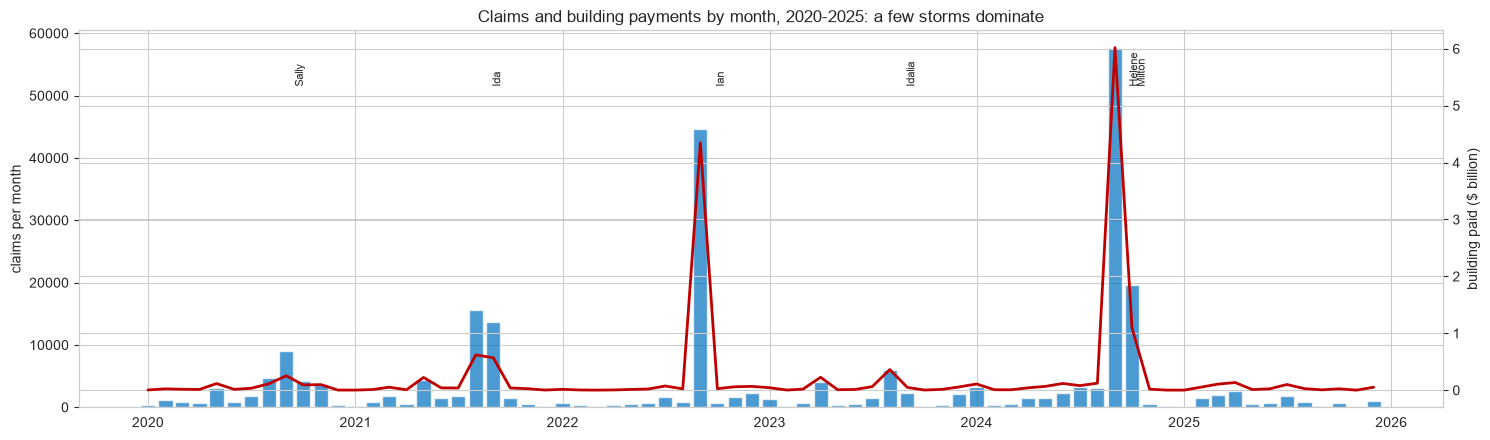

In [33]:
monthly = claims.set_index('dateOfLoss').resample('MS').agg({'id': 'size', 'amountPaidOnBuildingClaim': 'sum'})
fig, ax1 = plt.subplots(figsize=(15, 4.5))
ax1.bar(monthly.index, monthly['id'], width=25, color='#0070C0', alpha=0.7, label='claims')
ax1.set_ylabel('claims per month')
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['amountPaidOnBuildingClaim'] / 1e9, color='#C00000', lw=2, label='building paid ($bn)')
ax2.set_ylabel('building paid ($ billion)')
for event_name in ['Hurricane Ida', 'Hurricane Ian', 'Hurricane Helene', 'Hurricane Milton', 'Hurricane Sally', 'Hurricane Idalia']:
    event_date = claims.loc[claims['floodEvent'] == event_name, 'dateOfLoss'].median()
    if pd.notna(event_date):
        ax1.annotate(event_name.replace('Hurricane ', ''), (event_date, monthly['id'].max() * 0.9), rotation=90, fontsize=8)
ax1.set_title('Claims and building payments by month, 2020-2025: a few storms dominate')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_claims_by_month.png', dpi=120)
plt.show()

In [34]:
event_summary = (claims.groupby(claims['floodEvent'].fillna('(no named event)'))
                 .agg(claims=('id', 'size'), paid_rate=('building_paid_flag', 'mean'),
                      median_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
                      total_paid_musd=('amountPaidOnBuildingClaim', lambda s: s.sum() / 1e6),
                      large_loss_rate=('large_loss_flag', 'mean'), median_rain_3day=('rain_3day_mm', 'median'),
                      median_storm_distance=('storm_distance_km', 'median'))
                 .sort_values('claims', ascending=False).head(15))
print(event_summary.round(2).to_string())

                               claims  paid_rate  median_paid  total_paid_musd  large_loss_rate  median_rain_3day  median_storm_distance
floodEvent                                                                                                                              
Hurricane Helene                54363       0.92     95794.55          5898.11             0.26             53.98                 183.82
(no named event)                48606       0.76     15641.27          1277.05             0.03             68.86                2000.00
Hurricane Ian                   44736       0.83     70545.73          4361.61             0.20            159.22                  34.47
Hurricane Ida                   26476       0.82     26000.00          1114.38             0.06            184.88                  48.67
Hurricane Milton                19233       0.82     43462.68          1075.13             0.09            144.59                  69.52
Hurricane Sally                  7696    

## 11.2 Who gets paid? Flood zone, occupancy and foundation

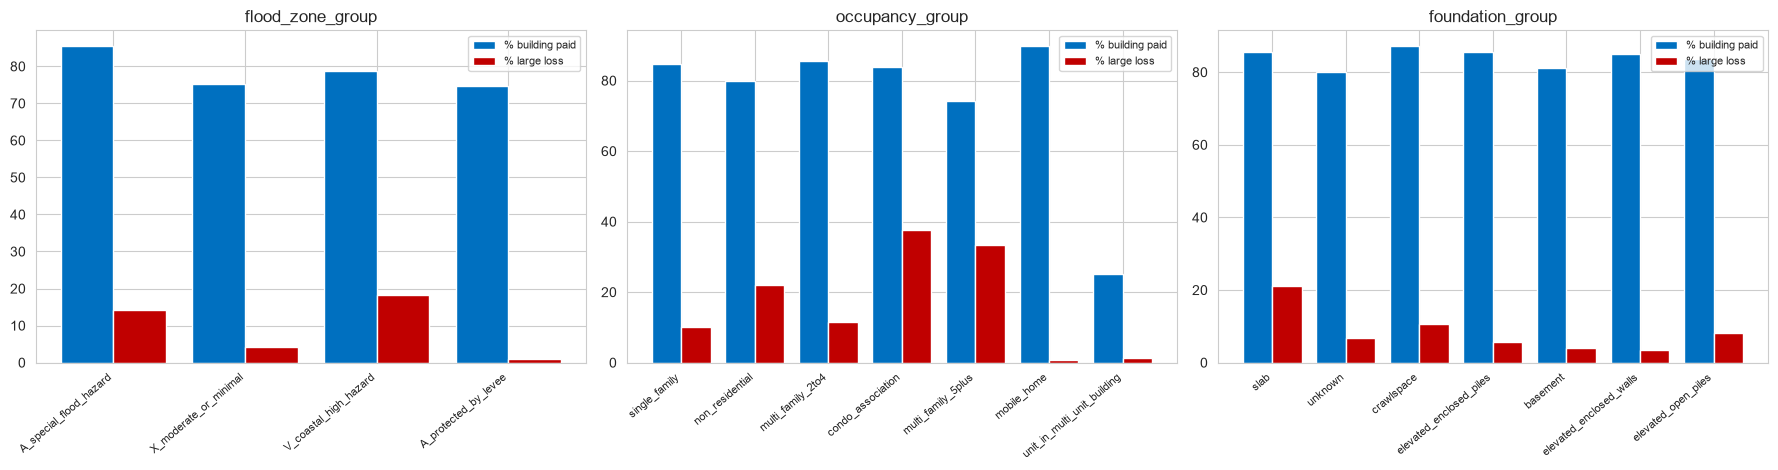

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, column in zip(axes, ['flood_zone_group', 'occupancy_group', 'foundation_group']):
    summary = claims.groupby(column).agg(paid_rate=('building_paid_flag', 'mean'), large_rate=('large_loss_flag', 'mean'),
                                         n=('id', 'size')).sort_values('n', ascending=False)
    summary = summary[summary['n'] > 500]
    x_positions = np.arange(len(summary))
    ax.bar(x_positions - 0.2, summary['paid_rate'] * 100, width=0.4, label='% building paid', color='#0070C0')
    ax.bar(x_positions + 0.2, summary['large_rate'] * 100, width=0.4, label='% large loss', color='#C00000')
    ax.set_xticks(x_positions)
    ax.set_xticklabels(summary.index, rotation=40, ha='right', fontsize=8)
    ax.set_title(column)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_rates_by_category.png', dpi=120)
plt.show()

## 11.3 Does outside data separate the outcomes? A first look

This is the first hint that the external data will help: the **rain** and **storm** distributions
differ between paid and unpaid claims, and between large and normal losses.

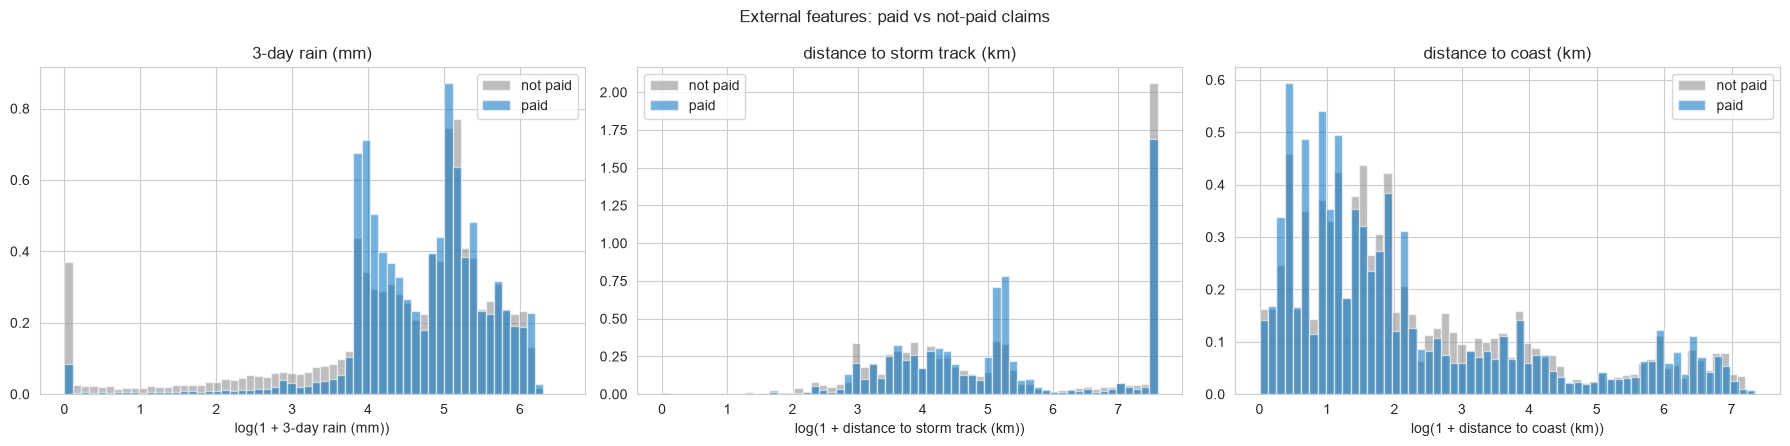

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, column, label in zip(axes, ['rain_3day_mm', 'storm_distance_km', 'coast_distance_km'],
                             ['3-day rain (mm)', 'distance to storm track (km)', 'distance to coast (km)']):
    for flag_value, color, name in [(0, '#888888', 'not paid'), (1, '#0070C0', 'paid')]:
        values = claims.loc[claims['building_paid_flag'] == flag_value, column]
        ax.hist(np.log1p(values), bins=60, alpha=0.55, color=color, density=True, label=name)
    ax.set_xlabel(f'log(1 + {label})')
    ax.set_title(label)
    ax.legend()
plt.suptitle('External features: paid vs not-paid claims')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_external_features_vs_paid.png', dpi=120)
plt.show()

---
# Section 12: Spatial Maps

Aggregation (Lecture 03, Section 7.2: combining rows) by county. We map counties with at least
20 claims, so that rates are not driven by one or two claims.

In [37]:
counties = gpd.read_file(f'zip://{RAW_DIR / "boundaries" / "cb_2023_us_county_20m.zip"}')
states = gpd.read_file(f'zip://{RAW_DIR / "boundaries" / "cb_2023_us_state_20m.zip"}')
conus_states = states[~states['STUSPS'].isin(['AK', 'HI', 'PR'])].to_crs(5070)
counties = counties[~counties['STUSPS'].isin(['AK', 'HI', 'PR'])].to_crs(5070)

county_summary = claims.groupby('county_geoid').agg(
    claims=('id', 'size'), total_paid_musd=('amountPaidOnBuildingClaim', lambda s: s.sum() / 1e6),
    paid_rate=('building_paid_flag', 'mean'), large_loss_rate=('large_loss_flag', 'mean'),
    median_rain_3day=('rain_3day_mm', 'median')).reset_index()
county_map = counties.merge(county_summary, left_on='GEOID', right_on='county_geoid', how='left')
county_map.to_parquet(PROCESSED_DIR / 'county_summary_map.parquet')
print('Counties with at least one claim:', county_summary.shape[0])

Counties with at least one claim: 2159


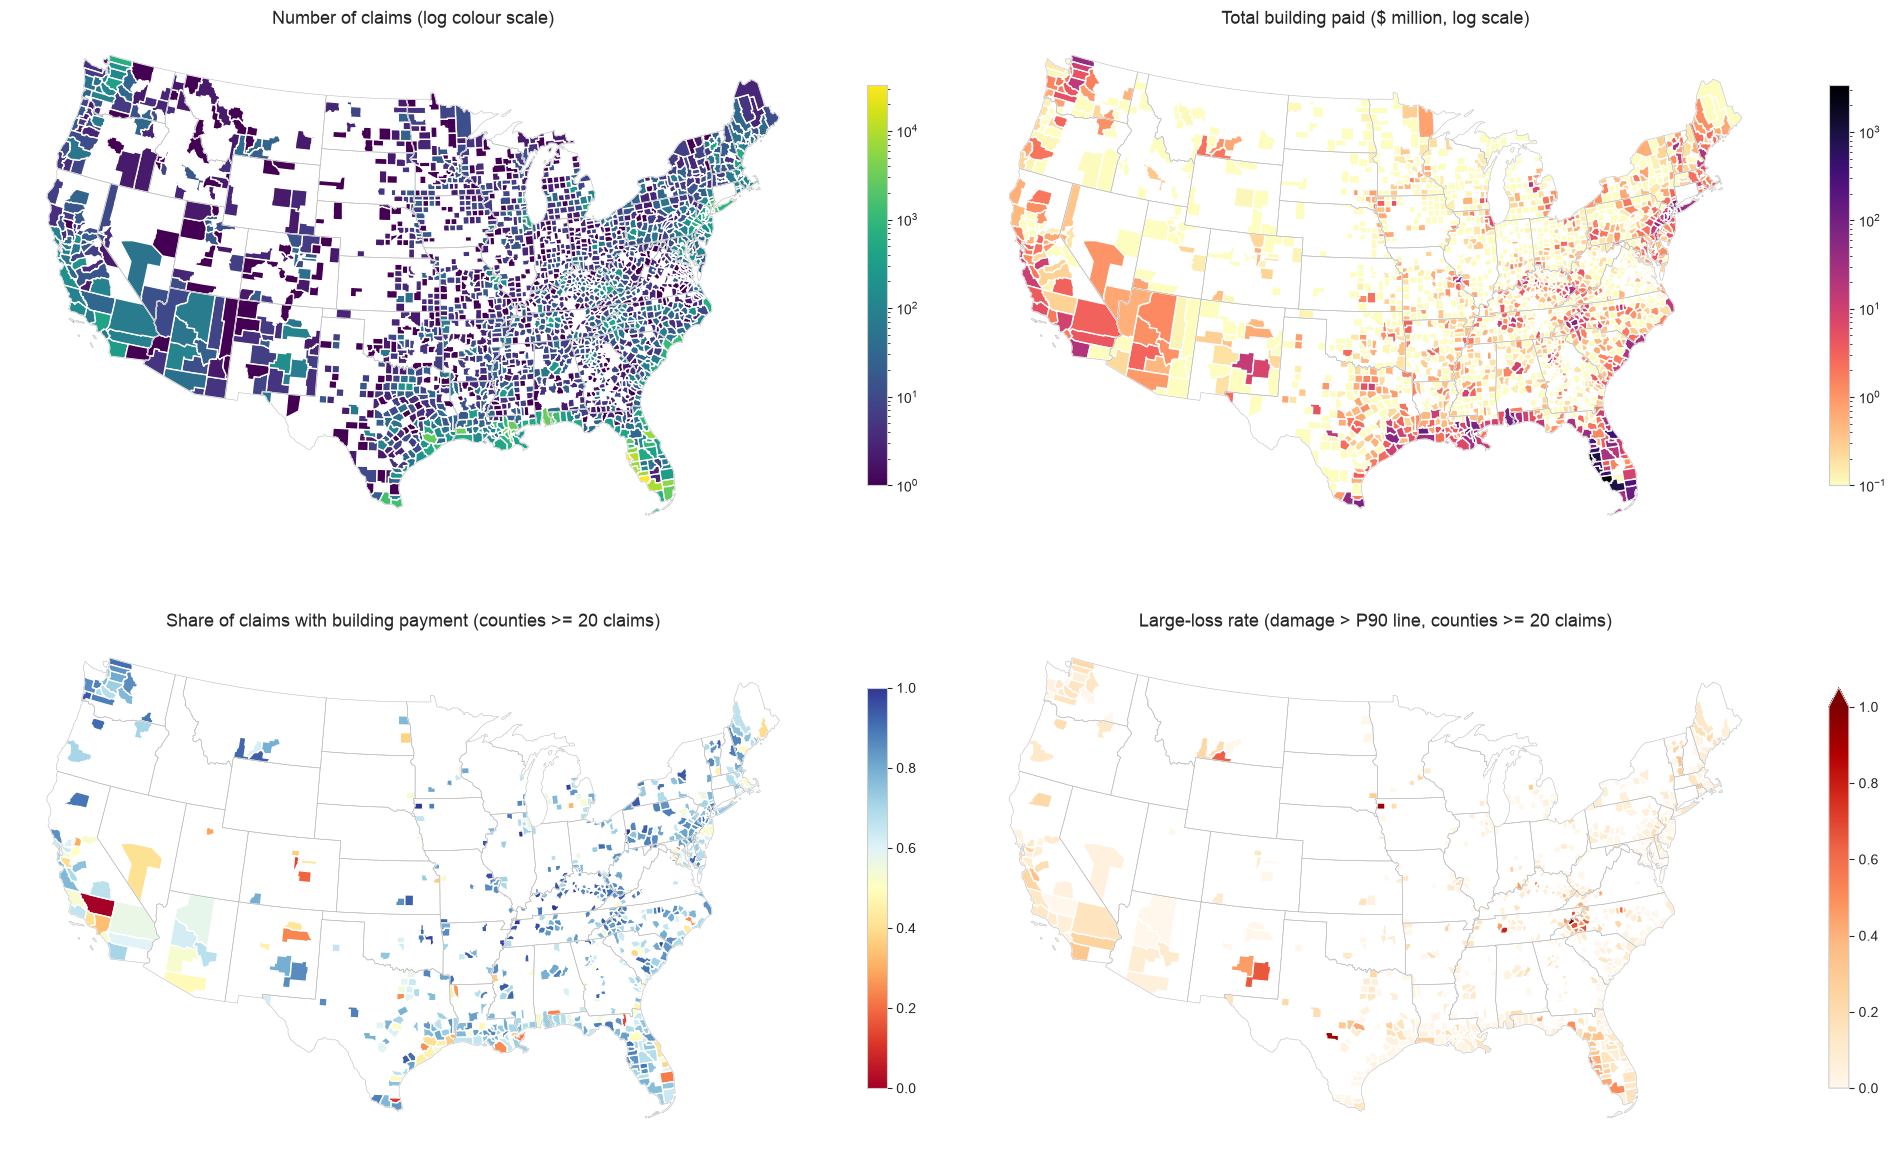

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(20, 13))
map_specs = [
    ('claims', 'Number of claims (log colour scale)', 'viridis', True),
    ('total_paid_musd', 'Total building paid ($ million, log scale)', 'magma_r', True),
    ('paid_rate', 'Share of claims with building payment (counties >= 20 claims)', 'RdYlBu', False),
    ('large_loss_rate', 'Large-loss rate (damage > P90 line, counties >= 20 claims)', 'OrRd', False),
]
for ax, (column, title, colormap, use_log) in zip(axes.ravel(), map_specs):
    conus_states.boundary.plot(ax=ax, color='#bbbbbb', linewidth=0.4)
    data = county_map[county_map['claims'] >= (1 if use_log else 20)]
    norm = mcolors.LogNorm(vmin=max(data[column].min(), 0.1), vmax=data[column].max()) if use_log else None
    value_limit = {'paid_rate': (0, 1), 'large_loss_rate': (0, 0.4)}.get(column, (None, None))
    data.plot(column=column, ax=ax, cmap=colormap, norm=norm, legend=True, vmin=value_limit[0] if not use_log else None,
              vmax=value_limit[1] if not use_log else None, legend_kwds={'shrink': 0.6})
    ax.set_title(title, fontsize=13)
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_county_maps.png', dpi=110)
plt.show()

**Reading the maps.** Claims cluster on the Gulf and Atlantic coasts, with inland pockets
along rivers (Kentucky 2022, Vermont 2023, western North Carolina 2024). The paid rate is high almost
everywhere claims are frequent. The large-loss rate is highest on the Gulf coast of Florida and
Louisiana, where storm surge hits, and in the Appalachian counties hit by Helene's rain.

## 12.1 Storm tracks over claims

The four storms with the most claims, with every claim point drawn underneath.

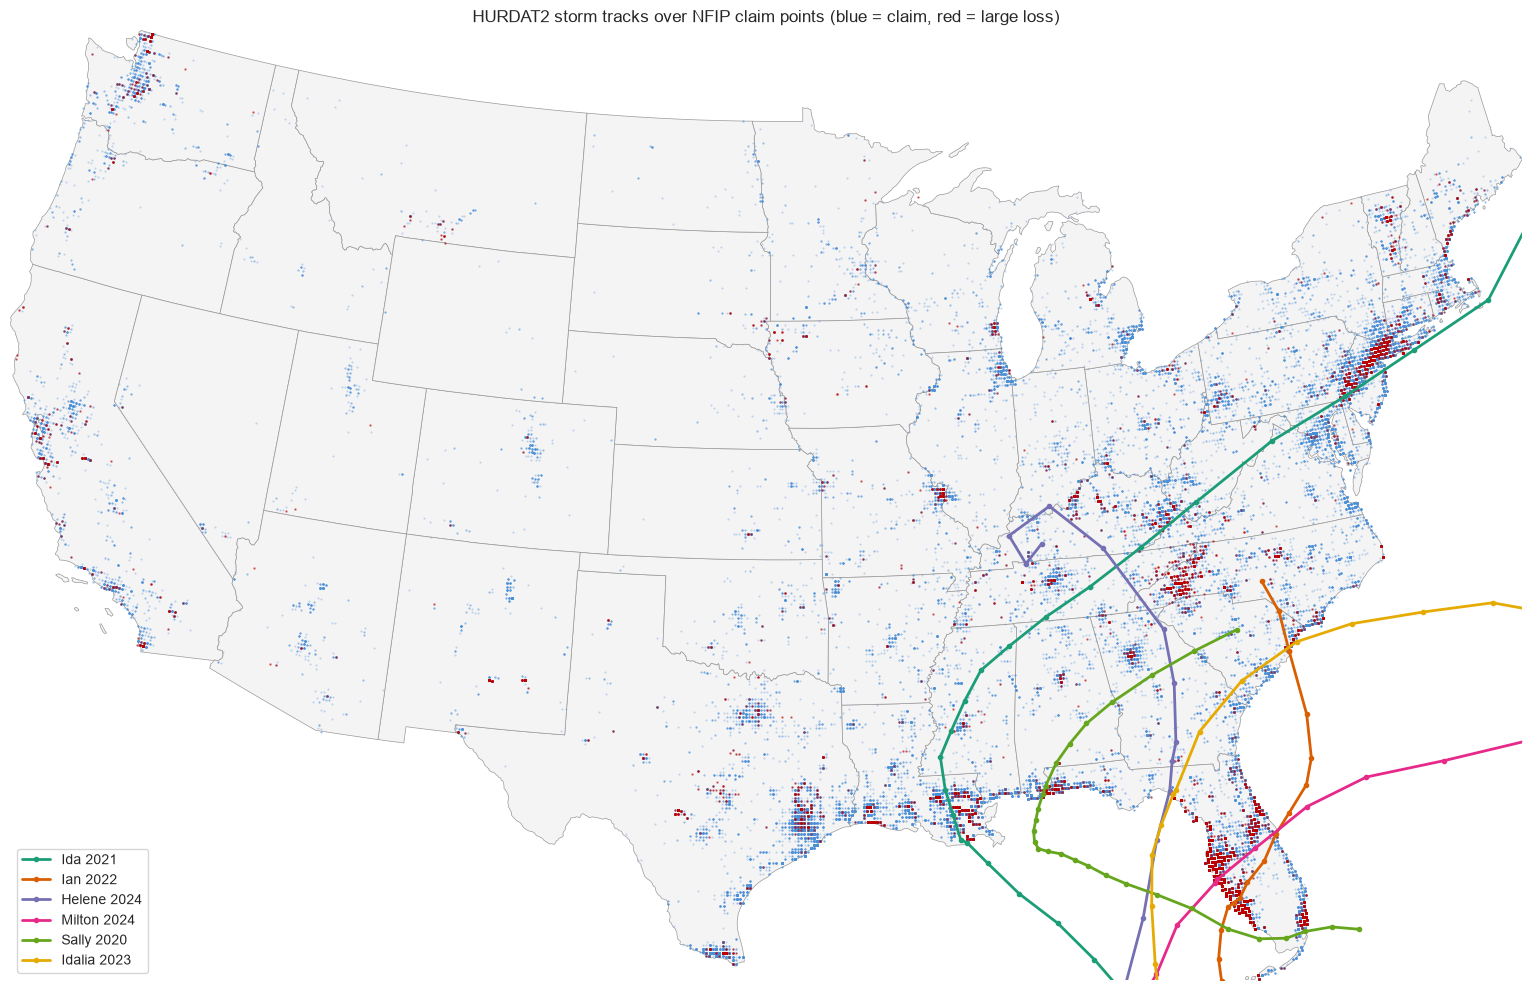

In [39]:
tracks = pd.read_parquet(PROCESSED_DIR / 'hurdat2_tracks_2019_2025.parquet')
storm_names_to_show = {'IDA': 2021, 'IAN': 2022, 'HELENE': 2024, 'MILTON': 2024, 'SALLY': 2020, 'IDALIA': 2023}
point_layer = gpd.GeoDataFrame(claims[['longitude', 'latitude', 'large_loss_flag']].copy(),
                               geometry=gpd.points_from_xy(claims['longitude'], claims['latitude']), crs=4326).to_crs(5070)
fig, ax = plt.subplots(figsize=(16, 10))
conus_states.plot(ax=ax, color='#f4f4f4', edgecolor='#999999', linewidth=0.5)
point_layer[point_layer['large_loss_flag'] != 1].plot(ax=ax, markersize=0.3, color='#4a90d9', alpha=0.3)
point_layer[point_layer['large_loss_flag'] == 1].plot(ax=ax, markersize=0.6, color='#C00000', alpha=0.5)
colors = sns.color_palette('Dark2', len(storm_names_to_show))
for color, (storm_name, storm_year) in zip(colors, storm_names_to_show.items()):
    one_track = tracks[(tracks['storm_name'] == storm_name) & (tracks['time_utc'].dt.year == storm_year)]
    track_line = gpd.GeoSeries(gpd.points_from_xy(one_track['longitude'], one_track['latitude']), crs=4326).to_crs(5070)
    ax.plot(track_line.x, track_line.y, '-o', color=color, markersize=3, lw=2, label=f'{storm_name.title()} {storm_year}')
ax.set_xlim(conus_states.total_bounds[0], conus_states.total_bounds[2])
ax.set_ylim(conus_states.total_bounds[1], conus_states.total_bounds[3])
ax.legend(loc='lower left')
ax.set_title('HURDAT2 storm tracks over NFIP claim points (blue = claim, red = large loss)')
ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_storm_tracks_over_claims.png', dpi=110)
plt.show()

## 12.2 Interactive map (folium)

An interactive version is saved to `figures/01_interactive_claims_map.html` (open it in a browser).
Each circle is one 0.1-degree point; size = number of claims, colour = large-loss rate.

In [40]:
import folium

point_summary = claims.groupby(['latitude', 'longitude']).agg(n_claims=('id', 'size'),
                                                              large_loss_rate=('large_loss_flag', 'mean'),
                                                              median_paid=('amountPaidOnBuildingClaim', 'median')).reset_index()
point_summary = point_summary[point_summary['n_claims'] >= 10]
interactive_map = folium.Map(location=[33, -88], zoom_start=5, tiles='cartodbpositron')
color_scale = plt.get_cmap('OrRd')
for _, row in point_summary.iterrows():
    rate = 0 if pd.isna(row['large_loss_rate']) else row['large_loss_rate']
    folium.CircleMarker(location=[row['latitude'], row['longitude']], radius=min(2 + np.sqrt(row['n_claims']) / 3, 15),
                        color=mcolors.to_hex(color_scale(min(rate * 2.5, 1))), fill=True, fill_opacity=0.6, weight=0,
                        tooltip=f"{int(row['n_claims'])} claims, large-loss {rate * 100:.0f}%, median paid ${row['median_paid']:,.0f}").add_to(interactive_map)
interactive_map.save(str(FIGURE_DIR / '01_interactive_claims_map.html'))
print('Saved interactive map with', len(point_summary), 'points')

Saved interactive map with 2058 points


---
# Section 13: Save the Clean Table

In [41]:
claims = claims.drop(columns=['is_train_period'])
clean_path = PROCESSED_DIR / 'claims_clean_2020_2025.parquet'
claims.to_parquet(clean_path, index=False)

summary_counts = {
    'rows_after_cleaning': len(claims),
    'columns_after_cleaning': claims.shape[1],
    'rows_removed_by_cleaning_steps': int(row_log_table.loc[2:, 'rows_removed'].sum()),
    'columns_dropped': len(drop_table),
    'columns_imputed': len(imputation_table),
    'placeholder_columns_fixed': len(placeholder_table),
    'large_loss_line_usd': large_loss_line,
}
json.dump(summary_counts, open(TABLE_DIR / '01_cleaning_summary.json', 'w'), indent=2)
print(json.dumps(summary_counts, indent=2))

{
  "rows_after_cleaning": 253124,
  "columns_after_cleaning": 119,
  "rows_removed_by_cleaning_steps": 22995,
  "columns_dropped": 30,
  "columns_imputed": 35,
  "placeholder_columns_fixed": 11,
  "large_loss_line_usd": 143519.0
}


---
# Summary of Notebook 01

| What | Count | Where to look |
|---|---|---|
| Row-level cleaning steps | 5 | `tables/01_row_cleaning_log.csv` |
| Placeholder codes turned into NaN | 11 columns | `tables/01_placeholder_codes.csv` |
| Columns dropped (with reason) | 30 | `tables/01_dropped_columns.csv` |
| Columns imputed (with method and value) | 35 | `tables/01_imputation_log.csv` |
| Leaking features | 19 entries (incl. one hidden missingness leak) | `tables/01_leakage_table.csv` |

**Key lessons**
- Many blanks are **structural**. Elevation is missing because Risk Rating 2.0 does not ask for it.
  Payment blanks mean 0 dollars.
- Large payments are real. We keep them and use log dollars.
- The strongest single predictors of payment are **post-loss** columns. They are leaks and are excluded.
- One leak was hidden: replacement cost looks like a building fact, but its blanks follow the claim process.
- The external rain and storm features already separate paid and unpaid claims in simple histograms.